# Copy-number analysis of human embryo biopsies from raw SNP-array data (GSE44994)

The notebook follows the order in which I worked through the problem: each block answers one question, and the
answer decides what I do in the next block.

**How to run (VS Code):** run cell 0.1 once with any Python 3 (it builds the `gse44994` conda environment and
registers a Jupyter kernel), then select the kernel **“Python (gse44994)”** (top-right) and run all cells.
First run: 1.2 GB download + ~40 min compute (CRLMM is the slowest step); results are cached in `results/`.

## 0. Setup
### 0.1 Build the environment (run once)
Creates the conda environment from `environment.yml` with `micromamba` (if missing: Homebrew on macOS, the
official binary on Linux),
installs two R packages that are not on conda (`pd.mapping250k.nsp`, `copynumber`) and registers the Jupyter
kernel.

In [1]:
import os
import shutil
import platform
import subprocess
from pathlib import Path

NB_DIR = Path.cwd()                                   # must be the notebook/ folder
ENV = Path.home() / "mamba" / "envs" / "gse44994"
MAMBA_ROOT = Path.home() / "mamba"


def sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


def r_package_installed(pkg):
    test = f"quit(status = !requireNamespace('{pkg}', quietly = TRUE))"
    result = subprocess.run([str(ENV / "bin" / "Rscript"), "-e", test])
    return result.returncode == 0


assert (NB_DIR / "environment.yml").exists(), "Open the notebook from the notebook/ folder"

# conda environment
if not (ENV / "bin" / "Rscript").exists():
    mamba = shutil.which("micromamba") or "/opt/homebrew/bin/micromamba"
    if not os.path.exists(mamba):
        if platform.system() == "Darwin":
            sh("brew install micromamba")
        else:                                            # Linux server: official static micromamba binary
            sh(f"mkdir -p '{MAMBA_ROOT}/bin' && curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest "
               f"| tar -xvj -C '{MAMBA_ROOT}' bin/micromamba")
            mamba = str(MAMBA_ROOT / "bin" / "micromamba")
    prefix = "CONDA_SUBDIR=osx-64 " if platform.machine() == "arm64" else ""
    sh(f"{prefix}MAMBA_ROOT_PREFIX='{MAMBA_ROOT}' '{mamba}' create -y -p '{ENV}' -f '{NB_DIR / 'environment.yml'}'")

# R packages from source (the conda post-link download of the annotation package is fragile)
(NB_DIR / "data").mkdir(exist_ok=True)
if not r_package_installed("pd.mapping250k.nsp"):
    tgz = NB_DIR / "data" / "pd.mapping250k.nsp_3.12.0.tar.gz"
    sh(f"curl -L --retry 10 -C - -o '{tgz}' "
       "https://bioconductor.org/packages/3.22/data/annotation/src/contrib/pd.mapping250k.nsp_3.12.0.tar.gz")
    sh(f"'{ENV}/bin/R' CMD INSTALL '{tgz}'")
if not r_package_installed("copynumber"):         # PCF segmentation; removed from Bioconductor, GitHub fork
    tgz = NB_DIR / "data" / "copynumber.tar.gz"
    sh(f"curl -L -o '{tgz}' https://github.com/igordot/copynumber/archive/refs/heads/master.tar.gz")
    sh(f"'{ENV}/bin/R' CMD INSTALL '{tgz}'")

# Jupyter kernel
sh(f"'{ENV}/bin/python' -m ipykernel install --user --name gse44994 --display-name 'Python (gse44994)'")
print("Environment ready. Now select the kernel 'Python (gse44994)' and continue below.")

$ '/Users/popova/mamba/envs/gse44994/bin/python' -m ipykernel install --user --name gse44994 --display-name 'Python (gse44994)'


Installed kernelspec gse44994 in /Users/popova/Library/Jupyter/kernels/gse44994
Environment ready. Now select the kernel 'Python (gse44994)' and continue below.


---
### ⏸ Switch the kernel to “Python (gse44994)” now, then run the cells below.
### 0.2 Imports, paths, helpers
R code is written as plain text in the cells and executed by `run_r(code, args, name)`: the code is saved to a file
and run with the environment's `Rscript`; file paths and numbers are passed as command-line arguments (read in R
with `commandArgs(TRUE)`). R and Python exchange plain TSV files.

In [2]:
import re
import sys
import gzip
import tarfile
import subprocess
import urllib.request
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.simplefilter("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

NB = Path.cwd()
DATA = NB / "data"
RES = NB / "results"
PRE = NB / "precomputed"            # slow results computed with exactly this code (see RUN_SLOW)
for folder in [DATA, RES, DATA / "cel", DATA / "chp"]:
    folder.mkdir(parents=True, exist_ok=True)

RSCRIPT = Path(sys.prefix) / "bin" / "Rscript"
assert RSCRIPT.exists(), "Run this notebook in the 'Python (gse44994)' kernel (cell 0.1)"

# True: recompute the two CBS segmentations (~40 min each) instead of loading them from precomputed/.
# The full simulation grid and PennCNV are always loaded from precomputed/.
RUN_SLOW = False

GAIN_COLOR, LOSS_COLOR, GREY, INK = "#cf222e", "#0969da", "#8c959f", "#1f2328"


def run_r(code, args, name):
    """Save R code to results/_<name>.R and run it with Rscript; args become commandArgs(TRUE) in R."""
    script = RES / f"_{name}.R"
    script.write_text(code)
    cmd = [str(RSCRIPT), str(script)] + [str(a) for a in args]
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout[-3000:])
    if result.stderr.strip():
        print("R messages/warnings:\n", result.stderr[-3000:])
    if result.returncode != 0:
        raise RuntimeError(f"R step '{name}' failed")


def download(url, dest):
    """curl, resuming from the size of the local file."""
    subprocess.run(["curl", "-L", "--retry", "10", "-C", "-", "-s", "-o", str(dest), url], check=True)


SMOKE_TEST = """
for (p in c("oligo", "crlmm", "pd.mapping250k.nsp", "DNAcopy", "copynumber", "affxparser", "data.table")) {
  suppressPackageStartupMessages(library(p, character.only = TRUE))
}
cat("R packages OK\\n")
"""
run_r(SMOKE_TEST, [], "smoke")

R packages OK

R messages/warnings:
 В пакете ‘oligoClasses’ не найдено методов для запросов: ‘mean’ во время загрузки ‘crlmm’



## 1. What are the data?
**Question:** what exactly is in GSE44994, and what can be used as ground truth? **Expectation:** one array per biopsy plus the authors' karyotype.

### 1.1 Sample metadata, cytobands and raw files
GEO stores the parental karyotype and the authors' final result for each biopsy in the sample characteristics.
The raw archive (`GSE44994_RAW.tar`, 1.16 GB) has one CEL file (raw intensities) and one CHP file (the authors'
GTYPE genotype calls) per array. NCBI throttles many single-file downloads, so I take the whole archive.

In [3]:
GEO_URL = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={}&targ=self&form=text&view=brief"


def geo_text(accession):
    return urllib.request.urlopen(GEO_URL.format(accession), timeout=60).read().decode()


def readable_header(path, n_bytes=3000):
    # CEL / CHP are binary: keep the readable words of the header
    start = path.read_bytes()[:n_bytes].decode("latin-1")
    return re.findall(r"[ -~]{6,}", start)


meta_file = DATA / "samples.tsv"
example_record_file = DATA / "example_geo_record.txt"
if not meta_file.exists():
    sample_ids = []
    for line in geo_text("GSE44994").splitlines():
        if line.startswith("!Series_sample_id"):
            sample_ids.append(line.split(" = ")[1])
    rows = []
    for gsm in sample_ids:
        row = {"gsm": gsm}
        for line in geo_text(gsm).splitlines():
            key, _, value = line.partition(" = ")
            if key == "!Sample_title":
                row["title"] = value
            if key == "!Sample_characteristics_ch1" and ": " in value:
                field, field_value = value.split(": ", 1)
                row[field] = field_value
        rows.append(row)
    table = pd.DataFrame(rows)
    table = table.rename(columns={"karyotype of patient donor": "parent_karyotype",
                                  "analysis result": "author_result",
                                  "result classification": "author_class"})
    table.to_csv(meta_file, sep="\t", index=False)

meta = pd.read_csv(meta_file, sep="\t")
meta["couple"] = meta["title"].str.rstrip("0123456789")     # siblings share the prefix
if not example_record_file.exists():
    example_record_file.write_text(geo_text(meta["gsm"][0]))

download("https://hgdownload.soe.ucsc.edu/goldenPath/hg19/database/cytoBand.txt.gz", DATA / "hg19.cytoBand.txt.gz")

n_cel = len(list((DATA / "cel").glob("*.CEL")))
n_chp = len(list((DATA / "chp").glob("*.CHP")))
if n_cel < len(meta) or n_chp < len(meta):
    archive = DATA / "GSE44994_RAW.tar"
    download("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE44nnn/GSE44994/suppl/GSE44994_RAW.tar", archive)
    with tarfile.open(archive) as tar:
        for member in tar.getmembers():
            subfolder = "cel" if ".CEL" in member.name else "chp"
            out_file = DATA / subfolder / member.name.replace(".gz", "")
            if not out_file.exists():
                compressed = tar.extractfile(member).read()
                out_file.write_bytes(gzip.decompress(compressed))

# raw input: one GEO record, the CEL / CHP headers, the cytoband table
print("GEO record", meta["gsm"][0])
for line in example_record_file.read_text().splitlines():
    if line.startswith("!Sample_title") or line.startswith("!Sample_characteristics_ch1"):
        print("   ", line)

cel_files = sorted((DATA / "cel").glob("*.CEL"))
chp_files = sorted((DATA / "chp").glob("*.CHP"))
print("\nCEL header:", readable_header(cel_files[0])[:3])
print("CHP header:", readable_header(chp_files[0])[:6])

print("\ncytoBand:")
with gzip.open(DATA / "hg19.cytoBand.txt.gz", "rt") as f:
    for i in range(3):
        print("   ", f.readline().rstrip())

# what we have now
cel_gb = sum(f.stat().st_size for f in cel_files) / 1e9
chp_gb = sum(f.stat().st_size for f in chp_files) / 1e9
print(f"\n{len(cel_files)} CEL ({cel_gb:.1f} GB), {len(chp_files)} CHP ({chp_gb:.2f} GB)")
print(len(meta), "biopsies,", meta.shape[1], "columns")
print()
print(meta["author_class"].value_counts().to_string())
meta[["gsm", "title", "couple", "parent_karyotype", "author_result", "author_class"]].head(25)

GEO record GSM1095396
    !Sample_title = SNP018ZXP2
    !Sample_characteristics_ch1 = cell type: trophectoderm cells
    !Sample_characteristics_ch1 = karyotype of patient donor: 45,XY,der(13;14)(q10;q10)
    !Sample_characteristics_ch1 = karyotype classification: Robertsonian translocation
    !Sample_characteristics_ch1 = analysis result: 46,XY
    !Sample_characteristics_ch1 = result classification: normal male

CEL header: ['affymetrix-calvin-intensity', '60000031079-1325838680-0000006334-0000018467-0000000041']
CHP header: ['GDMTAnalysis.DMBaseCall.1T', 'C:\\Program Files\\Affymetrix\\GeneChip\\Affy_Data\\Data\\SNP018ZXP2_(Mapping250K_Nsp).CEL', 'Mapping250K_Nsp', 'DynamicModel', 'CallCutoffPvalue', 'HetCallPValue']

cytoBand:
    chr1	0	2300000	p36.33	gneg
    chr1	2300000	5400000	p36.32	gpos25
    chr1	5400000	7200000	p36.31	gneg

47 CEL (3.1 GB), 47 CHP (0.26 GB)
47 biopsies, 8 columns

author_class
normal female                                                 31
normal male  

,gsm,title,couple,parent_karyotype,author_result,author_class
0,GSM1095396,SNP018ZXP2,SNP018ZXP,"45,XY,der(13;14)(q10;q10)","46,XY",normal male
1,GSM1095397,SNP027YLQ3,SNP027YLQ,"46,XY,t(6;22)(q12;p11.2)","46,XY",normal male
2,GSM1095398,SNP038WXJ2,SNP038WXJ,"45,XY,der(13;14)(q10;q10)","46,XX",normal female
3,GSM1095399,SNP017XLQ7,SNP017XLQ,"46,XY,t(1;17)(p22;q21)","46,XX",normal female
4,GSM1095400,SNP001CLM4,SNP001CLM,"46,XY,t(6;7)(q21;q22)","46,XX",normal female
5,GSM1095401,SNP002CL4,SNP002CL,"46,XY,t(2;7)(p13;p13)","46,XX",normal female
6,GSM1095402,SNP003DS3,SNP003DS,"46,XY,t(1;6)(q42;q25)","46,XX",normal female
7,GSM1095403,SNP010XHM2,SNP010XHM,"46,XX,t(9;13)(q32;q14)","46,XX",normal female
8,GSM1095404,SNP013TYY5,SNP013TYY,"46,XY,t(11;22)(q23;q11.2)","46,XX",normal female
9,GSM1095405,SNP027YLQ8,SNP027YLQ,"46,XY,t(6;22)(q12;p11.2)","46,XX",normal female


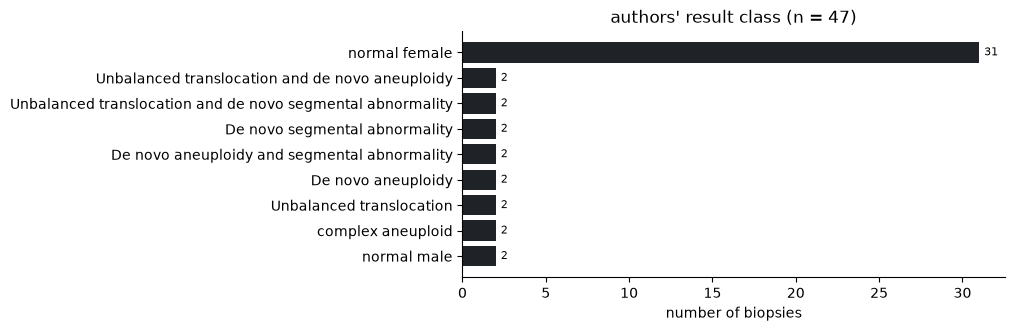

In [4]:
class_counts = meta["author_class"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(class_counts.index, class_counts.values, color=INK)
for i in range(len(class_counts)):
    ax.text(class_counts.values[i] + 0.3, i, str(class_counts.values[i]), va="center", fontsize=8)
ax.set_xlabel("number of biopsies")
ax.set_title(f"authors' result class (n = {len(meta)})")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 1.2 Karyotype strings -> genomic intervals (used for evaluation in blocks 6 and 9)
The ISCN-like strings (`46,XX,+9(pter-q33),-12(pter-q23)`, `45,XY,der(13;14)(q10;q10)`) are mapped to hg19
cytobands. A band missing at this resolution (e.g. 3q14) is mapped to the nearest lower band boundary.

In [5]:
cyto = pd.read_csv(DATA / "hg19.cytoBand.txt.gz", sep="\t", header=None, names=["chr", "start", "end", "band", "stain"])
cyto["chr"] = cyto["chr"].str.replace("chr", "")
CHROMS = [str(i) for i in range(1, 23)] + ["X"]
ACROCENTRIC = ["13", "14", "15", "21", "22"]
cyto = cyto[cyto["chr"].isin(CHROMS)]

CHRLEN = {}
CEN_START = {}
CEN_END = {}
for chrom in CHROMS:
    bands = cyto[cyto["chr"] == chrom]
    centromere = bands[bands["stain"] == "acen"]
    CHRLEN[chrom] = bands["end"].max()
    CEN_START[chrom] = centromere["start"].min()
    CEN_END[chrom] = centromere["end"].max()


def band_number(band):
    main, _, sub = band[1:].partition(".")
    if sub:
        return float(main + "." + sub.replace(".", ""))
    return float(main)


def band_position(chrom, band, side):
    """Genomic coordinate of a band; side = 'start' or 'end'."""
    if band == "pter":
        return 0
    if band == "qter":
        return CHRLEN[chrom]
    if band == "p10":
        return CEN_START[chrom]
    if band == "q10":
        return CEN_END[chrom]
    bands = cyto[cyto["chr"] == chrom]
    hit = bands[(bands["band"] == band) | bands["band"].str.startswith(band + ".")]
    if len(hit) > 0:
        if side == "start":
            return hit["start"].min()
        return hit["end"].max()
    # band absent at this resolution: closest lower band on the same arm
    requested_rank = band_number(band)
    same_arm = bands[bands["band"].str[0] == band[0]]
    same_arm_ranks = same_arm["band"].apply(band_number)
    lower = same_arm[same_arm_ranks <= requested_rank]
    if band[0] == "q":
        return lower["end"].max()
    return lower["start"].min()


def parse_region(chrom, spec):
    """Region text -> (start, end). Handles None (whole chr), 'p', 'q', 'pter-q33', 'q32.1qter', single band."""
    if spec is None:
        return 0, CHRLEN[chrom]
    if spec == "p":
        return 0, CEN_START[chrom]
    if spec == "q":
        return CEN_END[chrom], CHRLEN[chrom]
    match = re.match(r"^(pter|[pq][\d.]+)-?(qter|pter|[pq][\d.]+)$", spec)
    if match:
        first = band_position(chrom, match.group(1), "start")
        second = band_position(chrom, match.group(2), "end")
        return min(first, second), max(first, second)
    # a single band such as 'q13.13' is read as band -> telomere of that arm (ambiguous notation)
    if spec[0] == "q":
        return band_position(chrom, spec, "start"), CHRLEN[chrom]
    return 0, band_position(chrom, spec, "end")


def parse_result(text):
    """Authors' result -> (sex, list of events). Event = (chrom, start, end, 'gain'/'loss', original label)."""
    text = text.replace("；", ";").replace("）", ")").replace(";", ",")
    sex = None
    events = []
    for token in text.split(","):
        token = token.strip()
        if token == "" or token.isdigit():
            continue
        if re.fullmatch(r"X+Y*", token):
            sex = token
            continue
        sign, chrom, arm, spec = re.fullmatch(r"([+-])(\d+|X|Y)([pq])?(?:\((.*)\))?", token).groups()
        if spec is None:
            spec = arm
        start, end = parse_region(chrom, spec)
        kind = "gain" if sign == "+" else "loss"
        events.append((chrom, start, end, kind, token))
    return sex, events


def parse_parent(text):
    """Parental karyotype -> dict(kind='rob'/'rcp', chroms, bands, breakpoints)."""
    text = text.replace("）", ")")
    kind, chr1, chr2, band1, band2 = re.search(r"(der|rob|t)\((\w+);(\w+)\)\(([\w.]+);([\w.]+)\)", text).groups()
    robertsonian = kind in ("der", "rob") or (band1 == "q10" and band2 == "q10")
    breakpoints = [(chr1, band_position(chr1, band1, "start")), (chr2, band_position(chr2, band2, "start"))]
    return {"kind": "rob" if robertsonian else "rcp", "chroms": (chr1, chr2), "bands": (band1, band2),
            "breakpoints": breakpoints}


author_sex = []
author_events = []
parents = []
for row in meta.itertuples():
    sex, events = parse_result(row.author_result)
    autosomal = []
    for event in events:
        if event[0] != "X":
            autosomal.append(event)
    author_sex.append(sex)
    author_events.append(autosomal)
    parents.append(parse_parent(row.parent_karyotype))
meta["sex_author"] = author_sex
meta["events_author"] = author_events
meta["parent"] = parents
meta["n_author_events"] = [len(e) for e in author_events]

print(f"authors' autosomal events: {meta['n_author_events'].sum()} in {(meta['n_author_events'] > 0).sum()} biopsies")
meta[meta["n_author_events"] > 0][["title", "parent_karyotype", "author_result"]]

authors' autosomal events: 36 in 14 biopsies


,title,parent_karyotype,author_result
18,SNP016LLH2,"45,XX,der(13;14)(q10;q10)","47,XY,+9,-10(pter-q25),-17,-18,+20,+21,+21,+22"
19,SNP011ZJ3,"45,XY,der(13;15)(q10;q10)","45,XY,-15"
20,SNP038WXJ9,"45,XY,der(13;14)(q10;q10)","46,XX,+19"
21,SNP067CY3,"45,XY,t(13;14)(q10;q10)","45,XX,+20(q13.13),-22"
22,SNP067CY4,"45,XY,t(13;14)(q10;q10)","46,XY,+3p"
23,SNP097LYM5,"45,XY,der(13;14)(q10;q10)","45,XY,+2q,-14"
24,SNP093BLY4,"45,XX,der(14;21)(q10;q10)","48,XX,+21,+22"
25,SNP005XM2,"46,XX,t(1;2)(q23;q31)","XX,+1(q31-qter);-2(q32-qter),-7"
26,SNP017XLQ4,"46,XY,t(1;17)(p22;q21)","45,XY,-22"
27,SNP027YLQ5,"46,XY,t(6;22)(q12;p11.2)","46,XX,-6(q12-qter),+9(p22-p11.3),+10(q21.2-q23..."


**Observed:** 47 biopsies; the authors call 33 normal and 14 abnormal (36 autosomal events), with exactly two
biopsies per abnormal class (7 classes as stated above), so as in every class excatly 2 examples then authors uploaded specific data to GEO. This is a curated set and its abnormality rate says nothing about prevalence.
**Decision:** use the authors' calls only for evaluation, never inside the method.
**Next question:** what copy-number signal can I get from the raw CEL files?

## 2. From CEL files to allele intensities and genotypes
`oligo::snprma` quantile-normalises probe intensities to the HapMap target distribution of the 250K Nsp design and
summarises each SNP allele (A, B) by median polish (sense and antisense strands averaged). `oligo::crlmm` (CRLMM)
gives genotype calls. I also export per-SNP annotation: position (hg19), Nsp fragment length and probe GC - the
two covariates of WGA "genomic waves".

In [6]:
SNPRMA_CRLMM = """
suppressPackageStartupMessages({ library(oligo); library(pd.mapping250k.nsp); library(data.table) })
args <- commandArgs(TRUE)
cel_dir <- args[1]; crlmm_dir <- args[2]; out_file <- args[3]

cels <- sort(list.files(cel_dir, pattern = "CEL$", full.names = TRUE))
pre  <- snprma(read.celfiles(cels))                       # allele summaries (log2), per strand

if (!file.exists(file.path(crlmm_dir, "crlmm-calls.txt"))) {
  crlmm(cels, crlmm_dir, verbose = FALSE)                 # genotype calls 1=AA 2=AB 3=BB + confidence
}

# average sense and antisense strands (use the available one if the other is missing)
average_strands <- function(a, s) {
  m <- (a + s) / 2
  m[is.na(a)] <- s[is.na(a)]
  m[is.na(s)] <- a[is.na(s)]
  m
}
A <- average_strands(assayDataElement(pre, "antisenseAlleleA"), assayDataElement(pre, "senseAlleleA"))
B <- average_strands(assayDataElement(pre, "antisenseAlleleB"), assayDataElement(pre, "senseAlleleB"))

# annotation: position, Nsp fragment length, probe GC
con <- db(pd.mapping250k.nsp)
ann <- dbGetQuery(con, "select f.fsetid, f.man_fsetid as snp, f.chrom as chr, f.physical_pos as pos,
                        l.length as fraglen from featureSet f left join
                        (select fsetid, max(length) as length from fragmentLength group by fsetid) l
                        on f.fsetid = l.fsetid")
probes <- dbGetQuery(con, "select p.fsetid, s.seq from pmfeature p join sequence s on p.fid = s.fid")
probes$gc <- nchar(gsub("[AT]", "", probes$seq)) / nchar(probes$seq)
gc_per_snp <- tapply(probes$gc, probes$fsetid, mean)
ann$gc <- as.numeric(gc_per_snp[as.character(ann$fsetid)])
ann <- ann[match(rownames(A), ann$snp), ]

samples <- sub("_.*", "", basename(cels))
colnames(A) <- paste0("A_", samples)
colnames(B) <- paste0("B_", samples)
out <- data.table(ann[, c("snp", "chr", "pos", "fraglen", "gc")], round(A, 4), round(B, 4))
fwrite(out, out_file, sep = "\\t")
cat("done:", nrow(out), "SNPs\\n")
"""
summary_file = RES / "snp_summaries.tsv.gz"
if not summary_file.exists():
    run_r(SNPRMA_CRLMM, [DATA / "cel", RES / "crlmm", summary_file], "snprma_crlmm")

In [7]:
snps = pd.read_csv(summary_file, sep="\t", low_memory=False)
snps["chr"] = snps["chr"].astype(str)
snps = snps[snps["chr"].isin(CHROMS) & snps["pos"].notna()].copy()
chrom_order = {}
for i, chrom in enumerate(CHROMS):
    chrom_order[chrom] = i
snps["chr_index"] = snps["chr"].map(chrom_order)
snps = snps.sort_values(["chr_index", "pos"]).reset_index(drop=True)

SAMPLES = []
for column in snps.columns:
    if column.startswith("A_"):
        SAMPLES.append(column[2:])
meta = meta.set_index("gsm").loc[SAMPLES].reset_index()          # same order as the matrix columns

A = 2 ** snps[["A_" + s for s in SAMPLES]].to_numpy(float)       # linear intensities, SNP x sample
B = 2 ** snps[["B_" + s for s in SAMPLES]].to_numpy(float)

calls = pd.read_csv(RES / "crlmm" / "crlmm-calls.txt", sep="\t", index_col=0)
calls.columns = [c.split("_")[0] for c in calls.columns]
G = calls.reindex(snps["snp"])[SAMPLES].to_numpy(float)          # genotypes: 1 AA, 2 AB, 3 BB

POS = snps["pos"].to_numpy()
is_x = (snps["chr"] == "X").to_numpy()
is_auto = ~is_x
non_par_x = is_x & (POS > 2.7e6) & (POS < 154.9e6)              # exclude pseudo-autosomal regions
print(f"{len(snps):,} SNPs x {len(SAMPLES)} biopsies; chrX SNPs: {is_x.sum():,}")

261,961 SNPs x 47 biopsies; chrX SNPs: 5,700


**Observed:** A and B intensities and CRLMM genotypes for 261,961 SNPs x 47 biopsies, plus fragment length and probe
GC per SNP. **Decision:** build LRR from total intensity (A+B). **Next question:** what can serve as a reference?

## 3. LRR without normal reference arrays
### 3.1 Reference choice and X dosage
**Question:** without normal reference arrays, what can serve as a reference? **Hypothesis:** the cohort itself, if most biopsies are disomic at any locus; chrX intensity should then split X1-like and X2-like biopsies into two groups.

There are no normal reference arrays (the authors used 44 *unamplified* HapMap DNAs). All biopsies went through the
same PCR-based WGA. WGA introduces SNP-specific intensity distortions: some regions are amplified more efficiently than others. When the WGA sample is normalized against a non-WGA reference, these distortions manifest in the LRR (Log R Ratio) as spurious "gains" and "losses." so the best-matched reference is the cohort itself: for each biopsy and SNP, the **median of the
other 46 biopsies** (leave-one-out). This assumes that at any locus most biopsies are disomic (~70 % are normal).

chrX needs a two-copy reference, so I first classify each biopsy as X2-like or X1-like from the **total
intensity of non-PAR chrX** (not from metadata, and - see block 4 - not from heterozygosity). Y is not on the array.

Throughout the X analyses I use only the **non-pseudo-autosomal part of chrX** (hg19 chrX:2.7-154.9 Mb). The
pseudo-autosomal regions PAR1 and PAR2 are also present on chrY, so an XY embryo has two copies there; keeping them
would blur the one-copy signal of X1-like biopsies and add genuine heterozygous SNPs to the BAF control in block 4.

X dosage cut-off: -0.19 (gap from -0.31 to -0.06)
X dosage class vs authors' sex: 47 / 47 agree


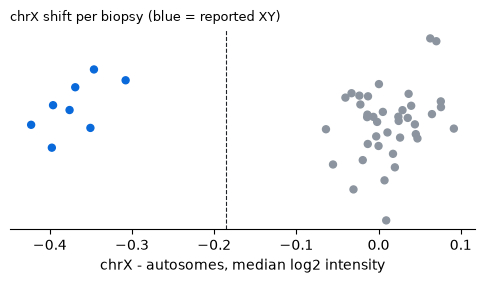

In [8]:
total = np.log2(A + B)
for j in range(len(SAMPLES)):                                   # centre each array on its autosomes
    total[:, j] = total[:, j] - np.nanmedian(total[is_auto, j])

x_shift = np.zeros(len(SAMPLES))
for j in range(len(SAMPLES)):
    x_shift[j] = np.nanmedian(total[non_par_x, j]) - np.nanmedian(total[is_auto, j])
x_shift = x_shift - np.median(x_shift)                          # most of the cohort is X2-like

sorted_shift = np.sort(x_shift)
gap = np.argmax(np.diff(sorted_shift))
X_CUT = (sorted_shift[gap] + sorted_shift[gap + 1]) / 2      # middle of the largest gap between biopsies
print(f"X dosage cut-off: {X_CUT:.2f} (gap from {sorted_shift[gap]:.2f} to {sorted_shift[gap + 1]:.2f})")

meta["x_shift"] = x_shift
meta["x_dosage"] = np.where(x_shift > X_CUT, "X2-like", "X1-like")
meta["sex_call"] = np.where(x_shift > X_CUT, "XX", "XY")       # X1-like reported as XY (Y not assayed)
n_agree = (meta["sex_call"] == meta["sex_author"]).sum()
print(f"X dosage class vs authors' sex: {n_agree} / {len(meta)} agree")

colors = []
for sex in meta["sex_author"]:
    colors.append(LOSS_COLOR if sex == "XY" else GREY)
jitter = np.random.default_rng(1).normal(0, 0.02, len(meta))
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.scatter(x_shift, jitter, c=colors, s=25)
ax.axvline(X_CUT, color=INK, lw=0.8, ls="--")
ax.set_yticks([])
ax.set_xlabel("chrX - autosomes, median log2 intensity")
ax.set_title("chrX shift per biopsy (blue = reported XY)", loc="left", fontsize=9)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

**Observed:** two clearly separated groups of chrX intensity that agree with the authors' sex in 47/47. Bonus: the same 8 X1-like biopsies in block 3.3 provide an internal calibration-that is, they show how much LRR corresponds to the loss of a single copy (-0.31 instead of the theoretical -1).
**Decision:** use the X2-like biopsies as the two-copy reference for chrX.
**Next question:** after building the LRR, how much technical noise and waviness is left?

### 3.2 Leave-one-out reference + wave correction
**Question:** how much technical structure is left after the correction by reference? **Expectation:** trends with fragment length and GC typical for PCR-WGA.

Per biopsy: `LRR = log2(A+B) - median(other biopsies)`; for chrX the reference uses X2-like biopsies only.
PCR-WGA and the Nsp-adaptor PCR create intensity trends with fragment length and GC ("waves"); I remove them with
a robust binned-median trend on each covariate (fitted on autosomes, applied genome-wide).

In [9]:
is_female = (meta["x_dosage"] == "X2-like").to_numpy()
LRR = np.empty_like(total)
for j in range(len(SAMPLES)):
    others = np.arange(len(SAMPLES)) != j
    reference_auto = np.nanmedian(total[is_auto][:, others], axis=1)
    reference_x = np.nanmedian(total[is_x][:, others & is_female], axis=1)
    LRR[is_auto, j] = total[is_auto, j] - reference_auto
    LRR[is_x, j] = total[is_x, j] - reference_x


def binned_trend(y, x, n_bins=50):
    """Robust 1-D trend: median of y in quantile bins of x, linearly interpolated."""
    ok = np.isfinite(y) & np.isfinite(x)
    edges = np.unique(np.quantile(x[ok], np.linspace(0, 1, n_bins + 1)))
    bin_centres = []
    bin_medians = []
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = ok & (x >= low) & (x <= high)
        if in_bin.sum() > 50:
            bin_centres.append(np.median(x[in_bin]))
            bin_medians.append(np.median(y[in_bin]))
    return np.interp(x, bin_centres, bin_medians)


fragment_bp = snps["fraglen"].fillna(snps["fraglen"].median())
fragment_bp = fragment_bp.clip(lower=50).to_numpy()
fragment_length = np.log10(fragment_bp)
probe_gc = snps["gc"].fillna(snps["gc"].median()).to_numpy()

sd_before = np.nanmedian(np.nanstd(LRR[is_auto], axis=0))
sd_before_each = np.nanstd(LRR[is_auto], axis=0)               # kept for the QC figure below
for j in range(len(SAMPLES)):
    y = LRR[:, j] - np.nanmedian(LRR[is_auto, j])
    y_auto_only = np.where(is_auto, y, np.nan)                  # fit the trend on autosomes only
    y = y - binned_trend(y_auto_only, fragment_length)
    y_auto_only = np.where(is_auto, y, np.nan)
    y = y - binned_trend(y_auto_only, probe_gc)
    LRR[:, j] = y - np.nanmedian(y[is_auto])
sd_after = np.nanmedian(np.nanstd(LRR[is_auto], axis=0))
print(f"median per-SNP LRR SD: {sd_before:.3f} before -> {sd_after:.3f} after wave correction")

median per-SNP LRR SD: 0.544 before -> 0.543 after wave correction


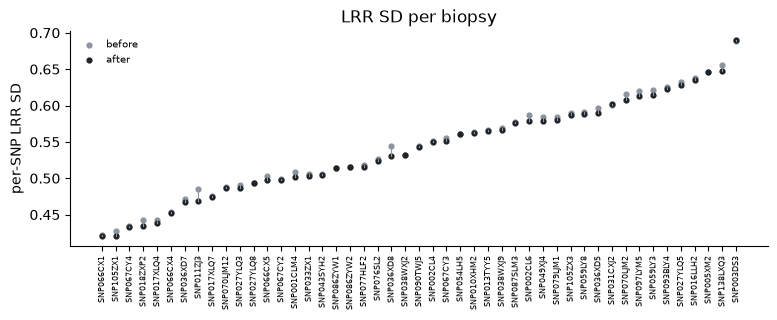

In [10]:
sd_after_each = np.nanstd(LRR[is_auto], axis=0)
order = np.argsort(sd_after_each)
fig, ax = plt.subplots(figsize=(9, 2.8))
for rank in range(len(order)):
    j = order[rank]
    ax.plot([rank, rank], [sd_before_each[j], sd_after_each[j]], color=GREY, lw=0.8)
ax.scatter(range(len(order)), sd_before_each[order], color=GREY, s=12, label="before")
ax.scatter(range(len(order)), sd_after_each[order], color=INK, s=12, label="after")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(meta["title"].values[order], rotation=90, fontsize=6)
ax.set_ylabel("per-SNP LRR SD")
ax.set_title("LRR SD per biopsy")
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Observed:** the per-SNP SD hardly changes (0.544 -> 0.543): single-SNP noise dominates. The correction targets slow
intensity trends; I keep it as a standard step but this check does not show a measurable gain, and I do not claim one.
**Next question:** how large is a real one-copy change compared with this noise?

### 3.3 How big is a one-copy change? Internal calibration on male chrX
**Question:** what LRR shift corresponds to one copy in these data? **Expectation:** compressed relative to the theoretical -1.

It was shown before but we will state it again

An X1-like biopsy has one X against a two-copy reference - a built-in one-copy loss. Its LRR gives the
**compressed** one-copy shift of these arrays (theory: log2(1/2) = -1). A gain is assumed to be compressed by the
same factor: `d_gain = d_loss · log2(3/2) / log2(1/2)`. No author labels are used.

In [11]:
male_x_lrr = []
for j in range(len(SAMPLES)):
    if not is_female[j]:
        male_x_lrr.append(np.nanmedian(LRR[non_par_x, j]))
D_LOSS = float(np.median(male_x_lrr))
D_GAIN = D_LOSS * np.log2(1.5) / np.log2(0.5)
print("chrX LRR of X1-like biopsies:", np.round(male_x_lrr, 2))
print(f"one-copy loss d_loss = {D_LOSS:.3f}; one-copy gain d_gain = {D_GAIN:.3f}")

chrX LRR of X1-like biopsies: [-0.35 -0.35 -0.29 -0.32 -0.29 -0.22 -0.39 -0.3 ]
one-copy loss d_loss = -0.307; one-copy gain d_gain = 0.180


**What this means.** Both one-copy shifts (-0.31 for a loss, +0.18 for a gain) are smaller than the noise of a
single SNP (SD ≈ 0.5), so a copy-number change cannot be seen from individual SNPs. I have to average over many SNPs,
i.e. segment the genome, and set the calling thresholds from the data. A gain shifts the LRR even less than a loss, so
gains are harder to detect and need longer segments. The simulations in block 8 confirm this.

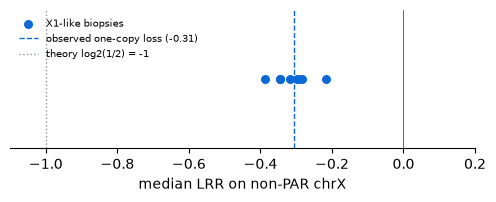

In [12]:
fig, ax = plt.subplots(figsize=(6, 1.8))
ax.scatter(male_x_lrr, np.zeros(len(male_x_lrr)), color=LOSS_COLOR, s=30, zorder=3, label="X1-like biopsies")
ax.axvline(D_LOSS, color=LOSS_COLOR, ls="--", lw=1, label=f"observed one-copy loss ({D_LOSS:.2f})")
ax.axvline(-1, color=GREY, ls=":", lw=1, label="theory log2(1/2) = -1")
ax.axvline(0, color=INK, lw=0.5)
ax.set_xlim(-1.1, 0.2)
ax.set_yticks([])
ax.set_xlabel("median LRR on non-PAR chrX")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

## 4. Can I use BAF?
### 4.1 BAF (PennCNV-style)
BAF is the fraction of the B allele at a SNP: 0 (AA), 0.5 (AB), 1 (BB); a trisomy adds bands at 1/3 and 2/3, a loss
removes the 0.5 band. I compute θ = 2/π·atan(B/A) (0 = only A, 1 = only B). Because A and B probes hybridise with
different efficiency, each SNP has its own θ positions for AA/AB/BB; I estimate them as the median θ of biopsies with
that CRLMM genotype (chrX: X2-like biopsies only) and rescale θ linearly so these centres become 0, 0.5 and 1.
SNPs whose clusters cannot be separated get no BAF.

In [13]:
theta = 2 / np.pi * np.arctan2(B, A)


def cluster_centre(genotype):
    """Median theta of all samples with this genotype, per SNP (chrX: X2-like samples only)."""
    use = (G == genotype)
    use[is_x] = use[is_x] & is_female
    return np.nanmedian(np.where(use, theta, np.nan), axis=1)


centre_aa = cluster_centre(1)
centre_ab = cluster_centre(2)
centre_bb = cluster_centre(3)
# fill missing centres (genotype not observed in the cohort)
centre_aa = np.where(np.isnan(centre_aa), np.nanmedian(centre_aa), centre_aa)
centre_bb = np.where(np.isnan(centre_bb), np.nanmedian(centre_bb), centre_bb)
centre_ab = np.where(np.isnan(centre_ab), (centre_aa + centre_bb) / 2, centre_ab)
centre_ab = np.clip(centre_ab, centre_aa + 0.02, centre_bb - 0.02)

aa = centre_aa[:, None]
ab = centre_ab[:, None]
bb = centre_bb[:, None]
baf_lower_half = 0.5 * (theta - aa) / (ab - aa)
baf_upper_half = 0.5 + 0.5 * (theta - ab) / (bb - ab)
BAF = np.where(theta < ab, baf_lower_half, baf_upper_half)
BAF = np.clip(BAF, 0, 1)
unresolved = (centre_bb - centre_aa) < 0.1                       # clusters too close or inverted
BAF[unresolved, :] = np.nan
print(f"BAF available for {np.mean(~unresolved):.1%} of SNPs")

BAF available for 100.0% of SNPs


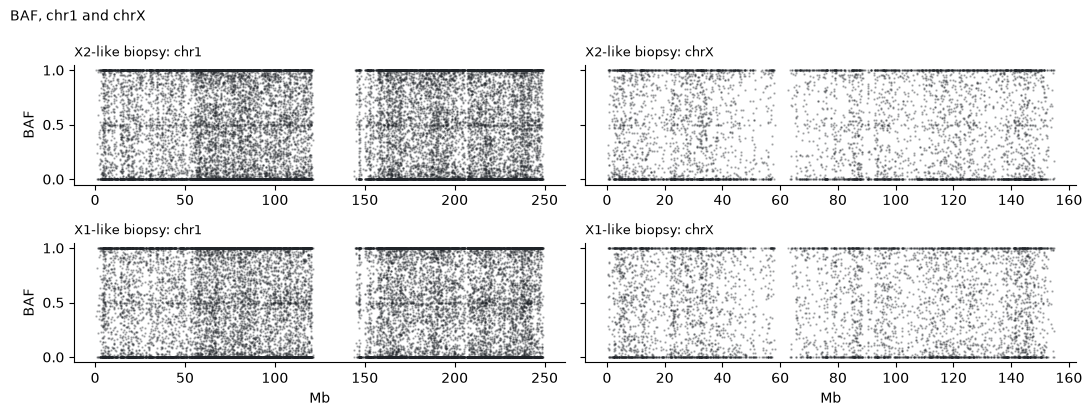

In [14]:
x2_example = meta[(meta["x_dosage"] == "X2-like") & meta["author_class"].str.startswith("normal")]["gsm"].iloc[0]
x1_example = meta[(meta["x_dosage"] == "X1-like") & meta["author_class"].str.startswith("normal")]["gsm"].iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(11, 4.2), sharey=True)
for r, gsm in enumerate([x2_example, x1_example]):
    j = SAMPLES.index(gsm)
    label = meta[meta["gsm"] == gsm]["x_dosage"].iloc[0]
    for c, chrom in enumerate(["1", "X"]):
        on_chrom = (snps["chr"] == chrom).to_numpy()
        axes[r, c].scatter(POS[on_chrom] / 1e6, BAF[on_chrom, j], s=0.5, color=INK, alpha=0.3, rasterized=True)
        axes[r, c].set_title(f"{label} biopsy: chr{chrom}", loc="left", fontsize=9)
        axes[r, c].spines[["top", "right"]].set_visible(False)
    axes[r, 0].set_ylabel("BAF")
axes[1, 0].set_xlabel("Mb")
axes[1, 1].set_xlabel("Mb")
plt.suptitle("BAF, chr1 and chrX", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.show()

*Next:* if BAF carries allelic information it should pass a simple control: a single X cannot be heterozygous.

But we can see already here that X1-like biopsies has a lot of SNP with the BAF in the interval from 0 to 1.


**Why BAF may not reflect the real alleles.** Before hybridisation the DNA of only 4-8 cells is amplified by PCR-based
WGA, which distorts the allele ratio: one allele of a heterozygote can drop out (the SNP looks homozygous), the two
alleles can be amplified unequally (BAF anywhere between 0 and 1), and cross-hybridisation gives B signal at
homozygous SNPs (they look heterozygous). If these effects dominate, BAF is mostly noise. A single X is a direct test:
in X1-like biopsies non-PAR chrX cannot be heterozygous, so heterozygote-like BAF values there should almost disappear.

### 4.2 Negative control: one X cannot be heterozygous
**Hypothesis:** if BAF reflects alleles, X1-like biopsies have almost no heterozygote-like values on chrX.

If BAF carried allelic information, the fraction of heterozygote-like BAF values (0.2-0.8) on non-PAR chrX should
collapse in X1-like biopsies.

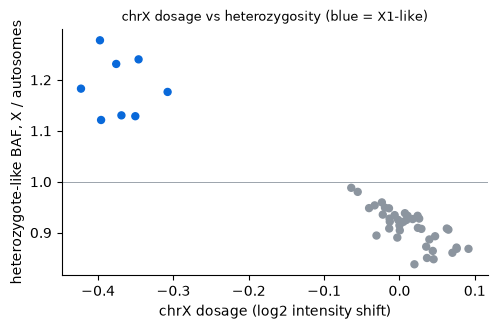

x_dosage
X1-like    1.18
X2-like    0.91


In [15]:
has_baf = np.isfinite(BAF)
het_like = has_baf & (BAF > 0.2) & (BAF < 0.8)
het_ratio = np.zeros(len(SAMPLES))
for j in range(len(SAMPLES)):
    het_on_x = het_like[non_par_x, j].sum() / has_baf[non_par_x, j].sum()
    het_on_auto = het_like[is_auto, j].sum() / has_baf[is_auto, j].sum()
    het_ratio[j] = het_on_x / het_on_auto
meta["het_ratio_x"] = het_ratio

colors = []
for dosage in meta["x_dosage"]:
    colors.append(LOSS_COLOR if dosage == "X1-like" else GREY)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.scatter(meta["x_shift"], het_ratio, c=colors, s=25)
ax.axhline(1, color=GREY, lw=0.6)
ax.set_xlabel("chrX dosage (log2 intensity shift)")
ax.set_ylabel("heterozygote-like BAF, X / autosomes")
ax.set_title("chrX dosage vs heterozygosity (blue = X1-like)", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(meta.groupby("x_dosage")["het_ratio_x"].median().round(2).to_string())

**Observed:** a single X cannot be heterozygous, so in X1-like biopsies heterozygote-like BAF values on chrX should
almost disappear. They do not: relative to the autosomes they are as frequent as in X2-like biopsies, even slightly
more (median ratio X/autosomes 1.18 vs 0.91). BAF values around 0.5 here come from noise, not from two different
alleles, so **BAF does not reflect the real alleles in these data**.
**Next question:** is this caused by my BAF construction (cluster centres based on CRLMM genotypes), or by the data
themselves? I check the authors' independent genotype calls.

### 4.3 Is it my genotyping? The authors' own GTYPE calls
**Question:** is the failure specific to my CRLMM-based BAF? **Expectation if it is the data:** the authors' independent GTYPE calls are also poor.

The CHP files contain the authors' GTYPE 4.1 calls and the gender GTYPE infers from X heterozygosity. If allelic
information is degraded by WGA of 4-8 cells, their calls should show it too. I compare them with my CRLMM calls on
the same arrays.

In [16]:
GTYPE_SUMMARY = """
suppressPackageStartupMessages({ library(affxparser); library(data.table) })
args <- commandArgs(TRUE)
chp_dir <- args[1]; out_file <- args[2]
rows <- list()
for (f in sort(list.files(chp_dir, "CHP$", full.names = TRUE))) {
  invisible(capture.output(chp <- readChp(f)))
  call <- chp$QuantificationEntries$Call            # Affymetrix codes: 6 AA, 7 BB, 8 AB, 11 no call
  rows[[f]] <- data.table(gsm = sub("_.*", "", basename(f)),
                          gtype_gender = chp$SummaryParameters$CalledGender,
                          call_rate = mean(call != 11),
                          het_rate = mean(call[call != 11] == 8))
}
fwrite(rbindlist(rows), out_file, sep = "\\t")
"""
gtype_file = RES / "gtype_summary.tsv"
if not gtype_file.exists():
    run_r(GTYPE_SUMMARY, [DATA / "chp", gtype_file], "gtype")

gtype = pd.read_csv(gtype_file, sep="\t")
gtype = gtype.merge(meta[["gsm", "title", "sex_author", "sex_call"]], on="gsm")
gtype["gtype_sex"] = gtype["gtype_gender"].replace({"M": "XY", "F": "XX"})
auto_calls = G[is_auto]
crlmm_het = (auto_calls == 2).sum(axis=0) / (~np.isnan(auto_calls)).sum(axis=0)   # among called SNPs
crlmm_het_by_gsm = dict(zip(SAMPLES, crlmm_het))
gtype["crlmm_het_rate"] = gtype["gsm"].map(crlmm_het_by_gsm)

gtype_sex_ok = (gtype["gtype_sex"] == gtype["sex_author"]).sum()
our_sex_ok = (gtype["sex_call"] == gtype["sex_author"]).sum()
print(f"GTYPE call rate: {gtype['call_rate'].min():.0%} - {gtype['call_rate'].max():.0%}")
print(f"heterozygous among called SNPs: GTYPE median {gtype['het_rate'].median():.0%}, "
      f"my CRLMM on the same arrays {gtype['crlmm_het_rate'].median():.0%}")
print(f"sex matches reported: GTYPE {gtype_sex_ok}/{len(gtype)}, X dosage {our_sex_ok}/{len(gtype)}")
gtype.sort_values("call_rate").head(8)

GTYPE call rate: 50% - 86%
heterozygous among called SNPs: GTYPE median 11%, my CRLMM on the same arrays 35%
sex matches reported: GTYPE 40/47, X dosage 47/47


,gsm,gtype_gender,call_rate,het_rate,title,sex_author,sex_call,gtype_sex,crlmm_het_rate
31,GSM1095427,M,0.502535,0.063489,SNP002CL6,XX,XX,XY,0.383546
6,GSM1095402,M,0.542567,0.047845,SNP003DS3,XX,XX,XY,0.367282
5,GSM1095401,M,0.549554,0.061948,SNP002CL4,XX,XX,XY,0.335389
25,GSM1095421,M,0.553492,0.081989,SNP005XM2,XX,XX,XY,0.351798
4,GSM1095400,M,0.558508,0.073022,SNP001CLM4,XX,XX,XY,0.341082
33,GSM1103273,F,0.608669,0.112452,SNP066CX4,XX,XX,XX,0.303562
16,GSM1095412,F,0.720246,0.084642,SNP059LY3,XX,XX,XX,0.379032
36,GSM1103276,F,0.721443,0.102958,SNP070LJM2,XX,XX,XX,0.387808


Allelic information is unreliable in these PCR-WGA biopsies (allele drop-out / drop-in); the two
genotyping algorithms even disagree on heterozygosity. The caller therefore uses LRR only

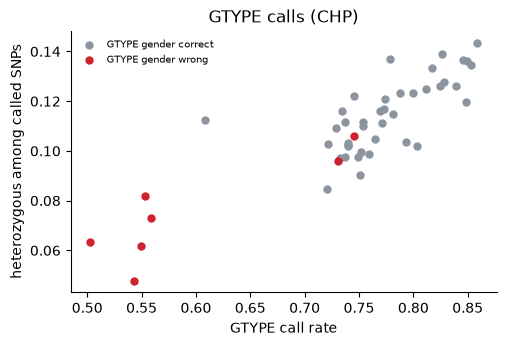

In [17]:
correct = gtype["gtype_sex"] == gtype["sex_author"]
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.scatter(gtype["call_rate"][correct], gtype["het_rate"][correct], color=GREY, s=25, label="GTYPE gender correct")
ax.scatter(gtype["call_rate"][~correct], gtype["het_rate"][~correct], color=GAIN_COLOR, s=25, label="GTYPE gender wrong")
ax.set_xlabel("GTYPE call rate")
ax.set_ylabel("heterozygous among called SNPs")
ax.set_title("GTYPE calls (CHP)")
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### X heterozygosity in the authors' genotype calls
**Question:** does the X negative control (4.2) also fail with the authors' GTYPE calls, and does it depend on array
quality? **Expectation if GTYPE calls carry allelic information:** in X1-like biopsies chrX should have almost no
heterozygous calls (ratio X/autosomes ≈ 0), while X2-like biopsies stay close to 1.

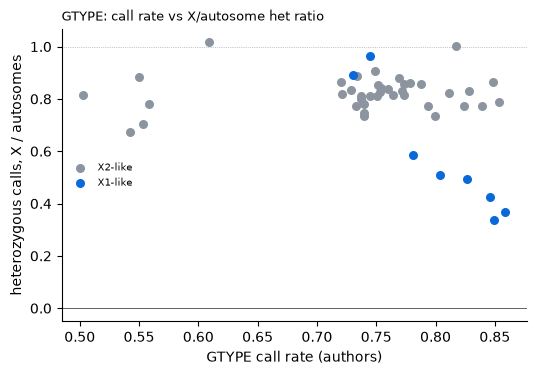

x_dosage
X1-like    0.50
X2-like    0.82


,title,call_rate,het_x,het_auto,het_ratio_x
0,SNP018ZXP2,0.859,0.054,0.145,0.368
26,SNP017XLQ4,0.849,0.046,0.138,0.336
1,SNP027YLQ3,0.846,0.059,0.138,0.426
19,SNP011ZJ3,0.827,0.069,0.141,0.494
29,SNP054LH5,0.804,0.052,0.103,0.507
22,SNP067CY4,0.781,0.068,0.116,0.585
18,SNP016LLH2,0.745,0.102,0.106,0.964
23,SNP097LYM5,0.731,0.086,0.096,0.893


In [18]:
# Per-biopsy heterozygosity of the authors' GTYPE calls on non-PAR chrX and on autosomes.
# CHP calls are stored in CDF unit order, so the unit names come from the Mapping250K_Nsp CDF.
cdf_gz = DATA / "Mapping250K_Nsp.cdf.gz"
cdf = DATA / "Mapping250K_Nsp.cdf"
if not cdf.exists():
    download("https://www.aroma-project.org/data/annotationData/chipTypes/Mapping250K_Nsp/Mapping250K_Nsp.cdf.gz", cdf_gz)
    cdf.write_bytes(gzip.decompress(cdf_gz.read_bytes()))

# SNP ids: non-PAR chrX and autosomes
x_ids_file = RES / "snps_nonpar_x.txt"
auto_ids_file = RES / "snps_autosomes.txt"
snps.loc[non_par_x, "snp"].to_csv(x_ids_file, index=False, header=False)
snps.loc[is_auto, "snp"].to_csv(auto_ids_file, index=False, header=False)

GTYPE_X_HET = """
suppressPackageStartupMessages({ library(affxparser); library(data.table) })
args <- commandArgs(TRUE)
chp_dir <- args[1]; cdf_file <- args[2]; x_file <- args[3]; auto_file <- args[4]; out_file <- args[5]
units <- readCdfUnitNames(cdf_file)
is_x <- units %in% readLines(x_file)
is_auto <- units %in% readLines(auto_file)
rows <- list()
for (f in sort(list.files(chp_dir, "CHP$", full.names = TRUE))) {
  invisible(capture.output(chp <- readChp(f)))
  call <- chp$QuantificationEntries$Call              # 6 AA, 7 BB, 8 AB, 11 no call
  called <- call != 11
  rows[[f]] <- data.table(gsm = sub("_.*", "", basename(f)),
                          het_x = mean(call[called & is_x] == 8),
                          het_auto = mean(call[called & is_auto] == 8))
}
fwrite(rbindlist(rows), out_file, sep = "\\t")
"""
gtype_x_file = RES / "gtype_x_het.tsv"
if not gtype_x_file.exists():
    run_r(GTYPE_X_HET, [DATA / "chp", cdf, x_ids_file, auto_ids_file, gtype_x_file], "gtype_x_het")

gtype_x = pd.read_csv(gtype_x_file, sep="\t")
gtype_x = gtype_x.merge(gtype[["gsm", "title", "call_rate"]], on="gsm")
gtype_x = gtype_x.merge(meta[["gsm", "x_dosage"]], on="gsm")
gtype_x["het_ratio_x"] = gtype_x["het_x"] / gtype_x["het_auto"]

fig, ax = plt.subplots(figsize=(6, 3.8))
for dosage, color in [("X2-like", GREY), ("X1-like", LOSS_COLOR)]:
    part = gtype_x[gtype_x["x_dosage"] == dosage]
    ax.scatter(part["call_rate"], part["het_ratio_x"], color=color, s=30, label=dosage)
ax.axhline(0, color=INK, lw=0.5)
ax.axhline(1, color=GREY, lw=0.5, ls=":")
ax.set_xlabel("GTYPE call rate (authors)")
ax.set_ylabel("heterozygous calls, X / autosomes")
ax.set_title("GTYPE: call rate vs X/autosome het ratio", loc="left", fontsize=9)
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(gtype_x.groupby("x_dosage")["het_ratio_x"].median().round(2).to_string())
gtype_x[gtype_x["x_dosage"] == "X1-like"].sort_values("call_rate", ascending=False)[
    ["title", "call_rate", "het_x", "het_auto", "het_ratio_x"]].round(3)

**Observed:** with the authors' GTYPE calls the X control is only partly passed. X2-like biopsies keep about 80 % of
the autosomal heterozygosity on chrX, X1-like biopsies 35-50 % in the best arrays and ~90 % in the worst ones, instead
of the expected ~0. GTYPE leaves ambiguous SNPs uncalled, so its remaining calls carry some allelic information, and
it improves with array quality, but even in the best biopsies a third to a half of the heterozygous calls on a single
X are false.
**Decision:** the allelic signal is weak and quality-dependent rather than absent; it is not reliable enough to call
losses or LOH, so I keep calling copy number from LRR only.

**Observed:** the authors' GTYPE calls have a low call rate (50-86 %) and the wrong gender in 7/47 biopsies. On a
single X they still keep 35-50 % of the autosomal heterozygosity in the best arrays and ~90 % in the worst (expected
~0). Their allelic signal is therefore better than my BAF, but weak and dependent on array quality. (Their 11 %
heterozygous calls and my 35 % use different denominators, so I do not compare them directly.)
**Decision:** in these PCR-WGA biopsies allelic information is not reliable enough to call losses or LOH, with either
genotyping method, so I call copy number from **LRR only**.
**Next question:** how to segment LRR and decide which segments are gains or losses without using the answers?

### 4.4 Can BAF be rescued by filtering SNPs?
**Question:** are the false heterozygotes on a single X concentrated in a subset of SNPs that could be removed?
Three candidate causes: neighbouring SNPs sharing one amplification product (spacing), long NspI fragments that
are less often intact after WGA (fragment length), and weak signal, where the probe of the other allele matters
(intensity, log2(A+B) before any reference). **Expectation:** if one of them explains the errors, the matching
filter should bring the false AB rate on a single X close to 0.

expected on a single X: 0
                              filter  SNP x biopsy  false AB
                            all SNPs         44840     0.337
                 SNPs >= 30 kb apart         17760     0.339
                   fragment < 400 bp          6072     0.294
            strongest 25 % of signal         11210     0.170
fragment < 400 bp and strongest 25 %          2011     0.104


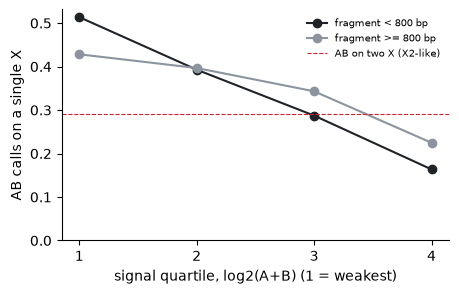

In [19]:
# false heterozygotes on a single X: X1-like biopsies, non-PAR chrX
x1 = ~is_female
x_rows = np.where(non_par_x)[0]
false_ab = G[x_rows][:, x1] == 2                       # SNP x X1-like biopsy
intensity = np.log2(A + B)[x_rows][:, x1]
fraglen = snps["fraglen"].to_numpy()[x_rows]

# thin the X SNPs to at least 30 kb apart
spaced = np.zeros(len(x_rows), dtype=bool)
last = -np.inf
for k in range(len(x_rows)):
    if POS[x_rows[k]] - last >= 30000:
        spaced[k] = True
        last = POS[x_rows[k]]

short = fraglen < 400
strong = intensity >= np.percentile(intensity, 75)
filters = pd.DataFrame([
    ("all SNPs", false_ab.size, false_ab.mean()),
    ("SNPs >= 30 kb apart", false_ab[spaced].size, false_ab[spaced].mean()),
    ("fragment < 400 bp", false_ab[short].size, false_ab[short].mean()),
    ("strongest 25 % of signal", false_ab[strong].size, false_ab[strong].mean()),
    ("fragment < 400 bp and strongest 25 %", false_ab[short[:, None] & strong].size,
     false_ab[short[:, None] & strong].mean()),
], columns=["filter", "SNP x biopsy", "false AB"])
print("expected on a single X: 0")
print(filters.round(3).to_string(index=False))

# false AB by signal quartile, short vs long fragments
quartile = np.digitize(intensity, np.percentile(intensity, [25, 50, 75]))
long_fragment = np.repeat((fraglen >= 800)[:, None], x1.sum(), axis=1)
x2_ab = np.mean(G[x_rows][:, is_female] == 2)

fig, ax = plt.subplots(figsize=(5, 3))
for is_long, color, label in [(False, INK, "fragment < 800 bp"), (True, GREY, "fragment >= 800 bp")]:
    rates = []
    for q in range(4):
        rates.append(false_ab[(quartile == q) & (long_fragment == is_long)].mean())
    ax.plot([1, 2, 3, 4], rates, "o-", color=color, label=label)
ax.axhline(x2_ab, color=GAIN_COLOR, ls="--", lw=0.8, label="AB on two X (X2-like)")
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("signal quartile, log2(A+B) (1 = weakest)")
ax.set_ylabel("AB calls on a single X")
ax.set_ylim(0, None)
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Observed:** on a single X, CRLMM calls 34 % of SNPs AB (expected 0). Thinning to >= 30 kb does not change it
(34 %); short fragments help a little (29 %); signal strength matters most: about 51 % false AB in the weakest
quartile vs 17 % in the strongest. Long fragments are weaker on average, so most of their effect goes through
intensity, with a small extra effect at good signal. Even the strictest filter (short fragment and strongest
signal) leaves 10 % false AB and keeps only ~4 % of the data.
**Decision:** filtering cannot rescue BAF: the errors come mainly from weak signal after PCR-WGA, not from SNP
density. Copy number is called from LRR only.
**Next question:** how to segment LRR and decide which segments are gains or losses?

## 5. Segmentation and copy-number states
### 5.1 Segmentation: piecewise constant fitting (`copynumber::pcf`)
**Question:** how to find regions of constant copy number in noisy, compressed LRR? **Expectation:** most segments near 0, a few clearly shifted.

PCF fits piecewise-constant means with a penalty γ per breakpoint, per chromosome arm (segments never cross the
centromere). Parameters fixed before any comparison (they are default): winsorised data, γ = 40, kmin = 5. Missing values are left
missing. Why PCF and not CBS: in the simulations of block 8 PCF detects more simulated steps with more precise
ends at similarly low extra-call rates, and the common CBS `sdundo` setting removes most real breakpoints here.

Each segment is then summarised by the **median** LRR of its SNPs (robust to WGA outliers; used by the state rule).

In [20]:
lrr_file = RES / "lrr.tsv.gz"
if not lrr_file.exists():
    lrr_table = pd.DataFrame(np.round(LRR, 4), columns=SAMPLES)
    lrr_table = pd.concat([snps[["snp", "chr", "pos"]], lrr_table], axis=1)
    lrr_table.to_csv(lrr_file, sep="\t", index=False)

PCF_SEGMENTS = """
suppressPackageStartupMessages({ library(copynumber); library(data.table) })
args <- commandArgs(TRUE)
lrr_file <- args[1]; out_file <- args[2]
d <- fread(cmd = paste("gzip -dc", shQuote(lrr_file)))
d <- d[chr != "X"]
d[, chr := as.integer(chr)]
setorder(d, chr, pos)
lrr <- data.frame(chrom = d$chr, pos = d$pos, d[, -(1:3)], check.names = FALSE)
w <- winsorize(lrr, assembly = "hg19", verbose = FALSE)
seg <- pcf(w, Y = lrr, assembly = "hg19", gamma = 40, kmin = 5, normalize = TRUE, fast = TRUE, verbose = FALSE)
out <- data.table(sample = seg$sampleID, arm = paste0(seg$chrom, seg$arm), start = seg$start.pos,
                  end = seg$end.pos, nsnp = seg$n.probes)
fwrite(out, out_file, sep = "\\t")
cat(nrow(out), "segments\\n")
"""
segment_file = RES / "segments_pcf.tsv"
if not segment_file.exists():
    run_r(PCF_SEGMENTS, [lrr_file, segment_file], "pcf")

# where each chromosome starts and ends in the sorted SNP table (to find a segment's SNPs quickly)
chrom_first_row = {}
chrom_last_row = {}
for chrom in CHROMS:
    rows_of_chrom = np.where(snps["chr"].to_numpy() == chrom)[0]
    chrom_first_row[chrom] = rows_of_chrom[0]
    chrom_last_row[chrom] = rows_of_chrom[-1] + 1


def add_segment_medians(segments):
    """Add 'lrr' = median LRR of the SNPs inside each segment (and 'chr', 'mb')."""
    segments = segments.copy()
    segments["chr"] = segments["arm"].astype(str).str[:-1]
    segments["mb"] = (segments["end"] - segments["start"]) / 1e6
    medians = []
    for row in segments.itertuples():
        first = chrom_first_row[row.chr]
        last = chrom_last_row[row.chr]
        positions = POS[first:last]                               # sorted positions of this chromosome
        lo = first + np.searchsorted(positions, row.start, side="left")
        hi = first + np.searchsorted(positions, row.end, side="right")
        sample_column = SAMPLES.index(row.sample)
        snp_values = LRR[lo:hi, sample_column]
        medians.append(np.nanmedian(snp_values))
    segments["lrr"] = medians
    return segments


segments = add_segment_medians(pd.read_csv(segment_file, sep="\t"))
print(f"{len(segments)} PCF segments ({len(segments) / len(SAMPLES):.0f} per biopsy)")

1969 PCF segments (42 per biopsy)


### 5.2 From segments to states - a rule calibrated on the data

PCF (section 5.1) only defines segment boundaries: for every biopsy it returns a list of segments (chromosome arm,
start, end, number of SNPs). I then take the median corrected LRR of the SNPs inside each segment. PCF does not say
which segments are abnormal. Almost every segment median differs a little from 0 just because of noise, so a rule is
needed that turns "segment with median x" into **loss / gain / normal**. This is the step where the copy-number
calls are actually made.

**Question:** which segments are gains or losses, without using the authors' answers?

1. **Noise scale (from the data).** Assuming most segments are approximately disomic, the central spread of all
   segment medians around 0 is used as a working null (empirical null, Efron 2004). It is measured robustly as
   1.4826 x MAD (Rousseeuw & Croux 1993), because a few real events inflate a plain SD (0.047 vs 0.022), and
   separately for three size classes, because the noise of a segment median falls with its number of SNPs (slope
   -0.52, close to -0.5 for independent noise; checked below).
2. **Label.** A segment (≥ 3 Mb and ≥ 100 SNPs) is a loss / gain if |median| > `max(4σ, 0.25·|d|)`.
   *Why 4σ:* for 1,911 tested segments the two-sided Bonferroni threshold at family-wise α = 0.1 is z = 4.04; 4σ
   corresponds to about 0.12 expected exceedances under a Gaussian null (nominal, not a measured false-call rate).
   *Why ≥ 3 Mb:* a pragmatic minimum; the simulations of block 8 detect no 2-Mb events and 90 % of 5-Mb full-copy
   losses (gains only 30 % at 5 Mb), so 3 Mb itself is not validated. `0.25·|d|` is only a safeguard (never binding
   here).
3. **Level** = median / one-copy shift d. d is measured on male chrX for losses (-0.31); the gain scale (+0.18) is
   derived from it, not measured. Level 1 is the calibrated one-copy amplitude; single events can depart from it.
   Calls with level < 0.7 are flagged as **lower-amplitude**. *Why 0.7:* it lies just below the eight author-free
   one-copy controls (single X of the X1-like biopsies: 0.71-1.26), but 4 % of 1,500-SNP control windows fall below
   it, and the levels of called segments show no gap at 0.7 (histogram below). So 0.7 is a descriptive flag: it does
   not prove mosaicism and does not exclude a full-copy change. Levels are reported for every call, and block 6
   shows all calls and the ≥ 0.7 subset side by side.
4. **Merge** adjacent same-direction segments with level difference < 0.5 into one event (similar in purpose to
   `mergeLevels`, Willenbrock & Fridlyand 2005, which merges levels by a statistical test; here a fixed rule). This
   joins the p- and q-arm pieces of a whole-chromosome aneuploidy (segments are per arm).

In [21]:
SIZE_CLASSES = [(0, 10), (10, 30), (30, 1e9)]                   # segment size classes in Mb


def size_class_of(mb):
    for i in range(len(SIZE_CLASSES)):
        low, high = SIZE_CLASSES[i]
        if low <= mb < high:
            return i


def noise_floor(segments):
    """Robust SD (1.4826 x MAD) of segment medians per size class."""
    usable = segments[(segments["mb"] >= 3) & (segments["nsnp"] >= 100)]
    sigmas = []
    for low, high in SIZE_CLASSES:
        values = usable[(usable["mb"] >= low) & (usable["mb"] < high)]["lrr"].dropna()
        mad = np.median(np.abs(values - np.median(values)))
        sigmas.append(1.4826 * mad)
    return sigmas


sigmas = noise_floor(segments)
print("empirical null sigma for segments <10, 10-30, >30 Mb:", np.round(sigmas, 3))

empirical null sigma for segments <10, 10-30, >30 Mb: [0.056 0.035 0.021]


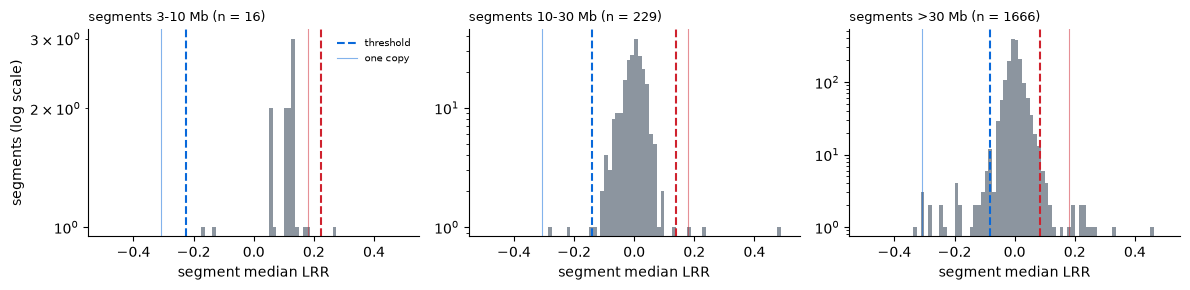

In [22]:
usable = segments[(segments["mb"] >= 3) & (segments["nsnp"] >= 100)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for i in range(len(SIZE_CLASSES)):
    low, high = SIZE_CLASSES[i]
    values = usable[(usable["mb"] >= low) & (usable["mb"] < high)]["lrr"].dropna()
    loss_cut = -max(4 * sigmas[i], 0.25 * abs(D_LOSS))
    gain_cut = max(4 * sigmas[i], 0.25 * D_GAIN)
    axes[i].hist(values, bins=np.linspace(-0.5, 0.5, 81), color=GREY)
    axes[i].set_yscale("log")
    axes[i].axvline(loss_cut, color=LOSS_COLOR, ls="--", label="threshold")
    axes[i].axvline(gain_cut, color=GAIN_COLOR, ls="--")
    axes[i].axvline(D_LOSS, color=LOSS_COLOR, lw=0.8, alpha=0.5, label="one copy")
    axes[i].axvline(D_GAIN, color=GAIN_COLOR, lw=0.8, alpha=0.5)
    title = f">{low:g} Mb" if high > 1e6 else f"{max(low, 3):g}-{high:g} Mb"
    axes[i].set_title(f"segments {title} (n = {len(values)})", loc="left", fontsize=9)
    axes[i].set_xlabel("segment median LRR")
    axes[i].spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("segments (log scale)")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

#### Checking the noise floor and the 4-sigma threshold on the data
**Question:** are the choices of step 1 supported by the data themselves (no author labels)? I check four things:
(1) does a robust SD differ from the plain SD, (2) does the noise of a segment median fall with the number of SNPs as
expected for independent noise (slope -0.5 on a log-log scale), (3) is the bulk of the distribution close to normal,
so that thresholds in units of sigma are meaningful, and how many segments lie beyond k sigma compared with pure
normal noise, (4) is the 0.25 x one-copy floor ever the binding threshold.

plain SD = 0.047, robust SD = 0.022, median = 0.001
noise slope (log-log) = -0.52, expected -0.5
central part (|z| < 3): mean = 0.01, skewness = 0.02
0-10 Mb: 4 sigma = 0.225, 0.25 x loss = 0.077, 0.25 x gain = 0.045
10-30 Mb: 4 sigma = 0.140, 0.25 x loss = 0.077, 0.25 x gain = 0.045
30-1e+09 Mb: 4 sigma = 0.083, 0.25 x loss = 0.077, 0.25 x gain = 0.045


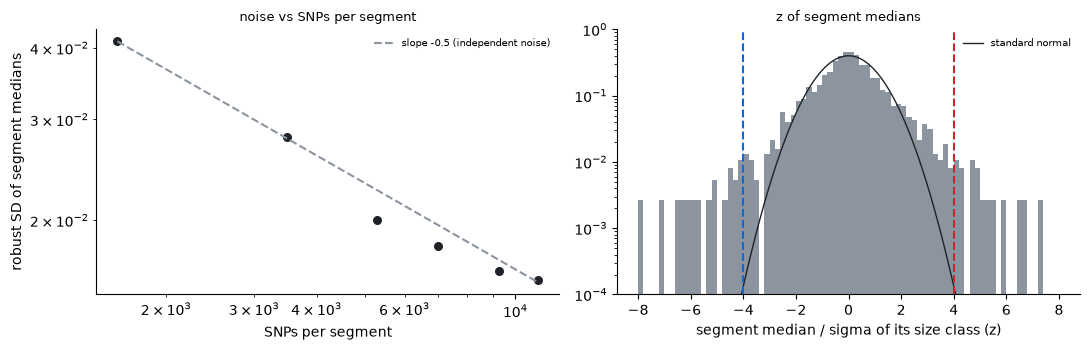

,threshold,segments beyond,expected if pure normal noise
0,2 sigma,267,87.0
1,3 sigma,116,5.2
2,4 sigma,69,0.1
3,5 sigma,45,0.0


In [23]:
from scipy import stats

usable = segments[(segments["mb"] >= 3) & (segments["nsnp"] >= 100)].dropna(subset=["lrr"]).copy()
values = usable["lrr"].to_numpy()

plain_sd = values.std()
robust_sd = 1.4826 * np.median(np.abs(values - np.median(values)))
print(f"plain SD = {plain_sd:.3f}, robust SD = {robust_sd:.3f}, median = {np.median(values):.3f}")

# noise in 6 groups of increasing SNP count
usable["snp_group"] = pd.qcut(usable["nsnp"], 6)
group_rows = []
for group, part in usable.groupby("snp_group", observed=True):
    part_values = part["lrr"].to_numpy()
    group_sd = 1.4826 * np.median(np.abs(part_values - np.median(part_values)))
    group_rows.append({"median_nsnp": part["nsnp"].median(), "robust_sd": group_sd, "segments": len(part)})
noise_by_size = pd.DataFrame(group_rows)
slope = np.polyfit(np.log(noise_by_size["median_nsnp"]), np.log(noise_by_size["robust_sd"]), 1)[0]
print(f"noise slope (log-log) = {slope:.2f}, expected -0.5")

z = []
for row in usable.itertuples():
    z.append(row.lrr / sigmas[size_class_of(row.mb)])
z = np.array(z)
central = z[np.abs(z) < 3]
print(f"central part (|z| < 3): mean = {central.mean():.2f}, skewness = {stats.skew(central):.2f}")
tail_rows = []
for k in [2, 3, 4, 5]:
    observed = int((np.abs(z) > k).sum())
    expected = len(z) * 2 * stats.norm.sf(k)
    tail_rows.append({"threshold": f"{k} sigma", "segments beyond": observed, "expected if pure normal noise": round(expected, 1)})

# which part of max(4 sigma, 0.25 x one copy) decides
for i in range(len(SIZE_CLASSES)):
    low, high = SIZE_CLASSES[i]
    print(f"{low}-{high:g} Mb: 4 sigma = {4 * sigmas[i]:.3f}, 0.25 x loss = {0.25 * abs(D_LOSS):.3f}, "
          f"0.25 x gain = {0.25 * D_GAIN:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].scatter(noise_by_size["median_nsnp"], noise_by_size["robust_sd"], color=INK, s=30)
reference = noise_by_size["robust_sd"].iloc[0] * (noise_by_size["median_nsnp"] / noise_by_size["median_nsnp"].iloc[0]) ** -0.5
axes[0].plot(noise_by_size["median_nsnp"], reference, color=GREY, ls="--", label="slope -0.5 (independent noise)")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("SNPs per segment")
axes[0].set_ylabel("robust SD of segment medians")
axes[0].legend(fontsize=7, frameon=False)
axes[0].set_title("noise vs SNPs per segment", fontsize=9)
bins = np.linspace(-8, 8, 81)
axes[1].hist(z, bins=bins, color=GREY, density=True)
grid = np.linspace(-8, 8, 400)
axes[1].plot(grid, stats.norm.pdf(grid), color=INK, lw=1, label="standard normal")
axes[1].axvline(-4, color=LOSS_COLOR, ls="--")
axes[1].axvline(4, color=GAIN_COLOR, ls="--")
axes[1].set_yscale("log")
axes[1].set_ylim(1e-4, 1)
axes[1].set_xlabel("segment median / sigma of its size class (z)")
axes[1].legend(fontsize=7, frameon=False)
axes[1].set_title("z of segment medians", fontsize=9)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
pd.DataFrame(tail_rows)

**Observed:** the plain SD of segment medians (0.047) is twice the robust SD (0.022): a few real events inflate it,
so the noise floor must be estimated robustly. The robust SD falls with the number of SNPs with a log-log slope of
-0.52, as expected for independent noise (-0.5); this is why sigma is estimated per size class. The central part of
the distribution is close to normal, so thresholds in units of sigma are meaningful. Beyond 4 sigma there are 69
segments where pure normal noise would give about 0.1, so these calls are not random noise; whether they are real
(including low-level mosaicism) or heavy-tailed WGA artefacts cannot be decided without an external reference. The
0.25 x one-copy floor never decides here: 4 sigma is always larger, so it only acts as a safeguard.

In [24]:
def label_segments(segments, sigmas, fixed_cutoff=None):
    """loss / gain / normal per segment.
    fixed_cutoff=None -> calibrated thresholds, a number x -> |median| > x."""
    types = []
    levels = []
    for row in segments.itertuples():
        if fixed_cutoff is None:
            sigma = sigmas[size_class_of(row.mb)]
            loss_cut = max(4 * sigma, 0.25 * abs(D_LOSS))
            gain_cut = max(4 * sigma, 0.25 * D_GAIN)
        else:
            loss_cut = fixed_cutoff
            gain_cut = fixed_cutoff
        large_enough = row.mb >= 3 and row.nsnp >= 100
        if large_enough and row.lrr < -loss_cut:
            types.append("loss")
            levels.append(row.lrr / D_LOSS)
        elif large_enough and row.lrr > gain_cut:
            types.append("gain")
            levels.append(row.lrr / D_GAIN)
        else:
            types.append("normal")
            levels.append(0.0)
    labelled = segments.copy()
    labelled["type"] = types
    labelled["level"] = levels
    return labelled


labelled = label_segments(segments, sigmas)
labelled["type"].value_counts()

type
normal    1900
loss        35
gain        34
Name: count, dtype: int64

In [25]:
def merge_events(labelled):
    """Merge neighbouring same-direction segments with level difference < 0.5.
    A normal segment >= 3 Mb ends the event; shorter ones are skipped."""
    events = []
    ordered = labelled.sort_values(["sample", "chr", "start"])
    for (sample, chrom), group in ordered.groupby(["sample", "chr"], sort=False):
        current = None
        for row in group.itertuples():
            if row.type == "normal":
                if row.mb >= 3 and current is not None:
                    events.append(current)
                    current = None
                continue
            same_event = (current is not None and row.type == current["type"]
                          and abs(row.level - current["level"]) < 0.5)
            if same_event:
                total_snps = current["nsnp"] + row.nsnp
                # SNP-weighted mean, approximates the whole-event median
                current["level"] = (current["level"] * current["nsnp"] + row.level * row.nsnp) / total_snps
                current["nsnp"] = total_snps
                current["end"] = row.end
                continue
            if current is not None:
                events.append(current)
            current = {"sample": sample, "chr": chrom, "start": row.start, "end": row.end,
                       "nsnp": row.nsnp, "type": row.type, "level": row.level}
        if current is not None:
            events.append(current)
    return pd.DataFrame(events, columns=["sample", "chr", "start", "end", "nsnp", "type", "level"])


def call_states(segments, fixed_cutoff=None):
    labelled = label_segments(segments, noise_floor(segments), fixed_cutoff)
    return merge_events(labelled)


events = merge_events(labelled)


def describe_event(row):
    """'+9:0-128' style label; low-level events show their level."""
    sign = "+" if row["type"] == "gain" else "-"
    text = f"{sign}{row['chr']}:{row['start'] / 1e6:.0f}-{row['end'] / 1e6:.0f}"
    if row["level"] < 0.7:
        text += f" (level {row['level']:.2f})"
    return text


our_calls = []
for gsm in meta["gsm"]:
    labels = []
    for _, row in events[events["sample"] == gsm].iterrows():
        labels.append(describe_event(row))
    our_calls.append("; ".join(labels))
meta["our_calls"] = our_calls
print(f"{len(events)} events in {events['sample'].nunique()} biopsies")
show = (meta["our_calls"] != "") | (meta["n_author_events"] > 0)
meta[show][["title", "author_result", "our_calls"]]

56 events in 19 biopsies


,title,author_result,our_calls
9,SNP027YLQ8,"46,XX",-18:19-78 (level 0.34); +6:62-171 (level 0.50)...
17,SNP059LY8,"46,XX",+12:38-134 (level 0.48); -14:20-107 (level 0.2...
18,SNP016LLH2,"47,XY,+9,-10(pter-q25),-17,-18,+20,+21,+21,+22",-10:0-135 (level 0.42); +12:0-134 (level 0.55)...
19,SNP011ZJ3,"45,XY,-15",-15:20-102
20,SNP038WXJ9,"46,XX,+19",+19:0-59
21,SNP067CY3,"45,XX,+20(q13.13),-22",-22:16-51 (level 0.61); -3:31-77 (level 0.29)
22,SNP067CY4,"46,XY,+3p",+3:0-198 (level 0.70)
23,SNP097LYM5,"45,XY,+2q,-14",-14:20-107 (level 0.63); +2:96-243
24,SNP093BLY4,"48,XX,+21,+22",+21:14-48; +22:16-51 (level 0.64)
25,SNP005XM2,"XX,+1(q31-qter);-2(q32-qter),-7",+1:182-249; -2:183-243; -7:0-159


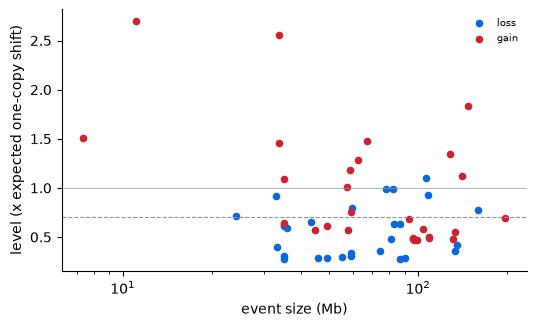

In [26]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for kind in ["loss", "gain"]:
    part = events[events["type"] == kind]
    ax.scatter((part["end"] - part["start"]) / 1e6, part["level"], color=(GAIN_COLOR if kind == "gain" else LOSS_COLOR), s=20, label=kind)
ax.axhline(0.7, color=GREY, ls="--", lw=0.8)
ax.axhline(1.0, color=GREY, lw=0.5)
ax.set_xscale("log")
ax.set_xlabel("event size (Mb)")
ax.set_ylabel("level (x expected one-copy shift)")
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

#### Is the 0.7 level cut seen in the data?
**Question:** do the called segments fall into two groups (around 1 = one copy, and lower), which would justify a
cut between one-copy-like and low-level calls? If not, what can anchor the cut without the authors' answers?
**Anchor:** the only author-free control with a known one-copy loss is the single X of the 8 X1-like biopsies. Its
level (median LRR of non-PAR chrX / d) shows how strong a real one-copy change looks in these data; I also check
1,500-SNP windows of the same X, closer to the size of a called segment.

single X of X1-like biopsies, level: [0.71 0.93 0.96 0.97 1.03 1.12 1.13 1.26]
1,500-SNP windows of the same X: 24, 5-95 % range 0.72-1.29, below 0.7: 4%
called segments below 0.7: 40 of 69


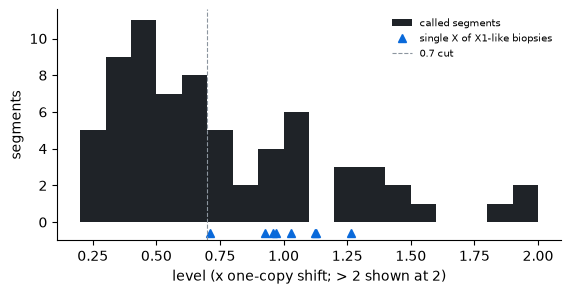

In [27]:
called_segments = labelled[labelled["type"] != "normal"]

# known one-copy losses: the single X of the X1-like biopsies
x1_columns = np.where(~is_female)[0]
x1_level = np.nanmedian(LRR[non_par_x][:, x1_columns], axis=0) / D_LOSS
x_rows = np.where(non_par_x)[0]
window_level = []
for j in x1_columns:
    for start in range(0, len(x_rows) - 1500, 1500):
        window_level.append(np.nanmedian(LRR[x_rows[start:start + 1500], j]) / D_LOSS)
window_level = np.array(window_level)

print("single X of X1-like biopsies, level:", np.sort(x1_level).round(2))
print(f"1,500-SNP windows of the same X: {len(window_level)}, 5-95 % range "
      f"{np.percentile(window_level, 5):.2f}-{np.percentile(window_level, 95):.2f}, "
      f"below 0.7: {np.mean(window_level < 0.7):.0%}")
print(f"called segments below 0.7: {(called_segments['level'] < 0.7).sum()} of {len(called_segments)}")

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(np.clip(called_segments["level"], 0, 2), bins=np.arange(0.2, 2.05, 0.1), color=INK, label="called segments")
ax.plot(x1_level, np.full(len(x1_level), -0.6), "^", color=LOSS_COLOR, ms=6, clip_on=False,
        label="single X of X1-like biopsies")
ax.axvline(0.7, color=GREY, ls="--", lw=0.8, label="0.7 cut")
ax.set_xlabel("level (x one-copy shift; > 2 shown at 2)")
ax.set_ylabel("segments")
ax.set_ylim(-1, None)
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Observed:** levels of called segments spread almost continuously from about 0.2 to 1.5 (40 of 69
below 0.7), with at most a shallow dip around 0.8 and no gap at 0.7, so the data do not show two clear groups. The anchor is the male X: the single X of the 8 X1-like biopsies has levels
0.71-1.26, so 0.7 lies just below every known one-copy loss in these data, and a call below 0.7 is weaker than any
of them. This anchor comes from the data, not from the literature. Limits: only 8 controls; the whole-X level is an
average, and some 1,500-SNP windows of the same X fall below 0.7; gains have no measured control (their scale is
derived from the loss).
**Decision:** keep 0.7 as a descriptive split, one-copy-like (≥ 0.7) vs low-level (< 0.7), and report both tiers;
the level is not a cell fraction, and low-level calls may be mosaicism or WGA noise.

**Observed:** 1,969 segments; null sigma 0.056 / 0.035 / 0.021 for small / medium / large segments; 69 segments
labelled (35 loss, 34 gain), merged into 56 events in 19 biopsies; levels spread almost continuously from about
0.2 to 1.5, so the split into full-copy (around 1) and low-level (< 0.7) calls is a convention, not two groups
seen in the data (histogram above).
**Next question:** how do these calls compare with the authors' karyotypes?

## 6. Agreement with the authors' karyotypes
**Question:** do my calls agree with the authors? **Expectation:** whole chromosomes agree well; segmental and low-level events less.

The authors' calls are an imperfect comparator (CNAT HMM vs unamplified HapMap reference, probably reviewed with
the parental karyotype known), so the numbers measure **agreement**, not clinical accuracy. Three levels:
* **biopsy** - abnormal vs normal;
* **arm** - 39 autosomal arms (5 acrocentric p arms excluded): gain / loss / normal;
* **event** - one-to-one matching: same chromosome and direction, the call covers ≥50 % of the authors' event
  (`+21,+21` counts as two events; the lone `+20(q13.13)` is read as q13.13->qter, which is ambiguous).

I report all calls and, separately, full-copy calls (level ≥ 0.7, defined in 5.2 before any comparison): low-level
calls are where WGA noise and possible mosaicism overlap, and the authors' pipeline would not report most of them.

In [28]:
ARMS = []
for chrom in CHROMS[:-1]:
    if chrom not in ACROCENTRIC:
        ARMS.append((chrom + "p", chrom, 0, CEN_START[chrom]))
    ARMS.append((chrom + "q", chrom, CEN_END[chrom], CHRLEN[chrom]))


def arm_states(event_list):
    """Arm -> 'gain'/'loss'/'normal' (an event must cover >= 30 % of the arm)."""
    states = {}
    for arm_name, chrom, start, end in ARMS:
        state = "normal"
        for ev_chrom, ev_start, ev_end, ev_type in event_list:
            overlap = min(end, ev_end) - max(start, ev_start)
            if ev_chrom == chrom and overlap >= 0.3 * (end - start):
                state = ev_type
        states[arm_name] = state
    return states


def match_events(truth, called):
    """Greedy one-to-one matching by overlap; returns the number of matched author events."""
    candidates = []
    for i in range(len(truth)):
        truth_chrom, truth_start, truth_end, truth_type = truth[i]
        for j in range(len(called)):
            call_chrom, call_start, call_end, call_type = called[j]
            if truth_chrom != call_chrom or truth_type != call_type:
                continue
            overlap = max(0, min(truth_end, call_end) - max(truth_start, call_start))
            if overlap >= 0.5 * (truth_end - truth_start):
                candidates.append((overlap, i, j))
    candidates.sort(reverse=True)                                 # largest overlaps first
    used_truth = set()
    used_called = set()
    for overlap, i, j in candidates:
        if i not in used_truth and j not in used_called:
            used_truth.add(i)
            used_called.add(j)
    return len(used_truth)


def per_biopsy_agreement(events):
    """One row per biopsy with the counts used by the summary."""
    rows = []
    for row in meta.itertuples():
        truth = []
        for chrom, start, end, kind, label in row.events_author:
            truth.append((chrom, start, end, kind))
        mine = events[events["sample"] == row.gsm]
        called = list(zip(mine["chr"], mine["start"], mine["end"], mine["type"]))
        truth_arms = arm_states(truth)
        called_arms = arm_states(called)
        arms_true = 0
        arms_called = 0
        arms_correct = 0
        for arm_name in truth_arms:
            if truth_arms[arm_name] != "normal":
                arms_true += 1
                if called_arms[arm_name] == truth_arms[arm_name]:
                    arms_correct += 1
            if called_arms[arm_name] != "normal":
                arms_called += 1
        rows.append({"title": row.title, "author_abnormal": len(truth) > 0, "called_abnormal": len(called) > 0,
                     "arms_true": arms_true, "arms_called": arms_called, "arms_correct": arms_correct,
                     "events_true": len(truth), "events_called": len(called),
                     "events_matched": match_events(truth, called)})
    return pd.DataFrame(rows)


def summarise(per_biopsy):
    """Biopsy-, arm- and event-level agreement in one row."""
    p = per_biopsy
    abnormal_found = (p["author_abnormal"] & p["called_abnormal"]).sum()
    normal_kept = (~p["author_abnormal"] & ~p["called_abnormal"]).sum()
    matched = p["events_matched"].sum()
    recall = matched / p["events_true"].sum()
    precision = matched / p["events_called"].sum() if p["events_called"].sum() > 0 else 0
    f1 = 2 * recall * precision / (recall + precision) if recall + precision > 0 else 0
    return {"abnormal_detected": f"{abnormal_found}/{p['author_abnormal'].sum()}",
            "normal_called_normal": f"{normal_kept}/{(~p['author_abnormal']).sum()}",
            "arm_sensitivity": round(p["arms_correct"].sum() / p["arms_true"].sum(), 2),
            "extra_arm_calls": int(p["arms_called"].sum() - p["arms_correct"].sum()),
            "events_matched": f"{matched}/{p['events_true'].sum()}",
            "event_recall": round(recall, 2), "event_precision": round(precision, 2), "F1": round(f1, 2)}


per_biopsy = per_biopsy_agreement(events)
disagreements = per_biopsy[(per_biopsy["events_matched"] != per_biopsy["events_true"]) |
                           (per_biopsy["events_called"] != per_biopsy["events_matched"])]
print("biopsies where the authors and I differ:")
print(disagreements.to_string(index=False))

comparison = {}
comparison["primary: PCF + calibrated rule (all calls)"] = summarise(per_biopsy)
# the same calls split by level: full-copy (>= 0.7) vs low-level
full_copy_events = events[events["level"] >= 0.7]
comparison["primary: full-copy calls only (level >= 0.7)"] = summarise(per_biopsy_agreement(full_copy_events))
low_level = events[events["level"] < 0.7]
print(f"low-level calls: {len(low_level)} in {low_level['sample'].nunique()} biopsies")
pd.DataFrame(comparison).T

biopsies where the authors and I differ:
     title  author_abnormal  called_abnormal  arms_true  arms_called  arms_correct  events_true  events_called  events_matched
SNP027YLQ8            False             True          0            3             0            0              3               0
 SNP059LY8            False             True          0            5             0            0              4               0
SNP016LLH2             True             True         12           17            12            8             11               7
 SNP067CY3             True             True          2            2             1            2              2               1
SNP027YLQ5             True             True          6            9             5            7              9               6
 SNP054LH5             True             True          0            0             0            1              2               0
 SNP002CL6             True             True          2            3  

,abnormal_detected,normal_called_normal,arm_sensitivity,extra_arm_calls,events_matched,event_recall,event_precision,F1
primary: PCF + calibrated rule (all calls),14/14,28/33,0.95,27,32/36,0.89,0.57,0.7
primary: full-copy calls only (level >= 0.7),11/14,33/33,0.63,0,19/36,0.53,0.9,0.67


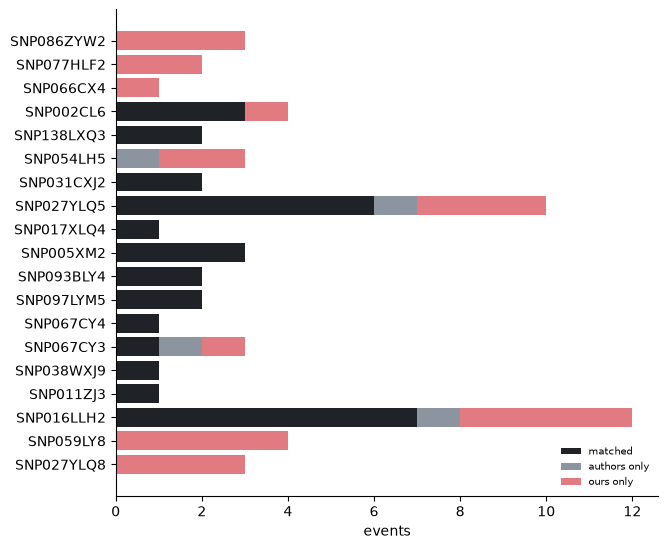

In [29]:
# biopsies with at least one event in either call set
shown = per_biopsy[(per_biopsy["events_true"] > 0) | (per_biopsy["events_called"] > 0)]
matched = shown["events_matched"].to_numpy()
authors_only = shown["events_true"].to_numpy() - matched
ours_only = shown["events_called"].to_numpy() - matched
fig, ax = plt.subplots(figsize=(7, 0.28 * len(shown) + 1))
ax.barh(shown["title"], matched, color=INK, label="matched")
ax.barh(shown["title"], authors_only, left=matched, color=GREY, label="authors only")
ax.barh(shown["title"], ours_only, left=matched + authors_only, color=GAIN_COLOR, alpha=0.6, label="ours only")
ax.set_xlabel("events")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Observed:** all 14 abnormal biopsies detected and 32/36 authors' events matched (recall 0.89), but 5 author-normal
biopsies get calls, so precision is 0.57. Keeping only full-copy calls gives 33/33 normal biopsies: every call in an
author-normal biopsy is low-level (level < 0.7). The price is recall 0.53, because the authors also report
low-level events.
**Decision:** report the two tiers separately (full-copy vs low-level) instead of tuning a threshold on the answers.
**Next question:** is this trade-off specific to my method? -> compare with standard methods (7) and measure what
can be detected at all (8).

### 6.1 Look at the profiles
Grey dots: per-SNP LRR; black: 2-Mb running median; thick lines: called events at their level (red gain, blue loss).
Bars on top: the authors' events (upper) and ours (lower).

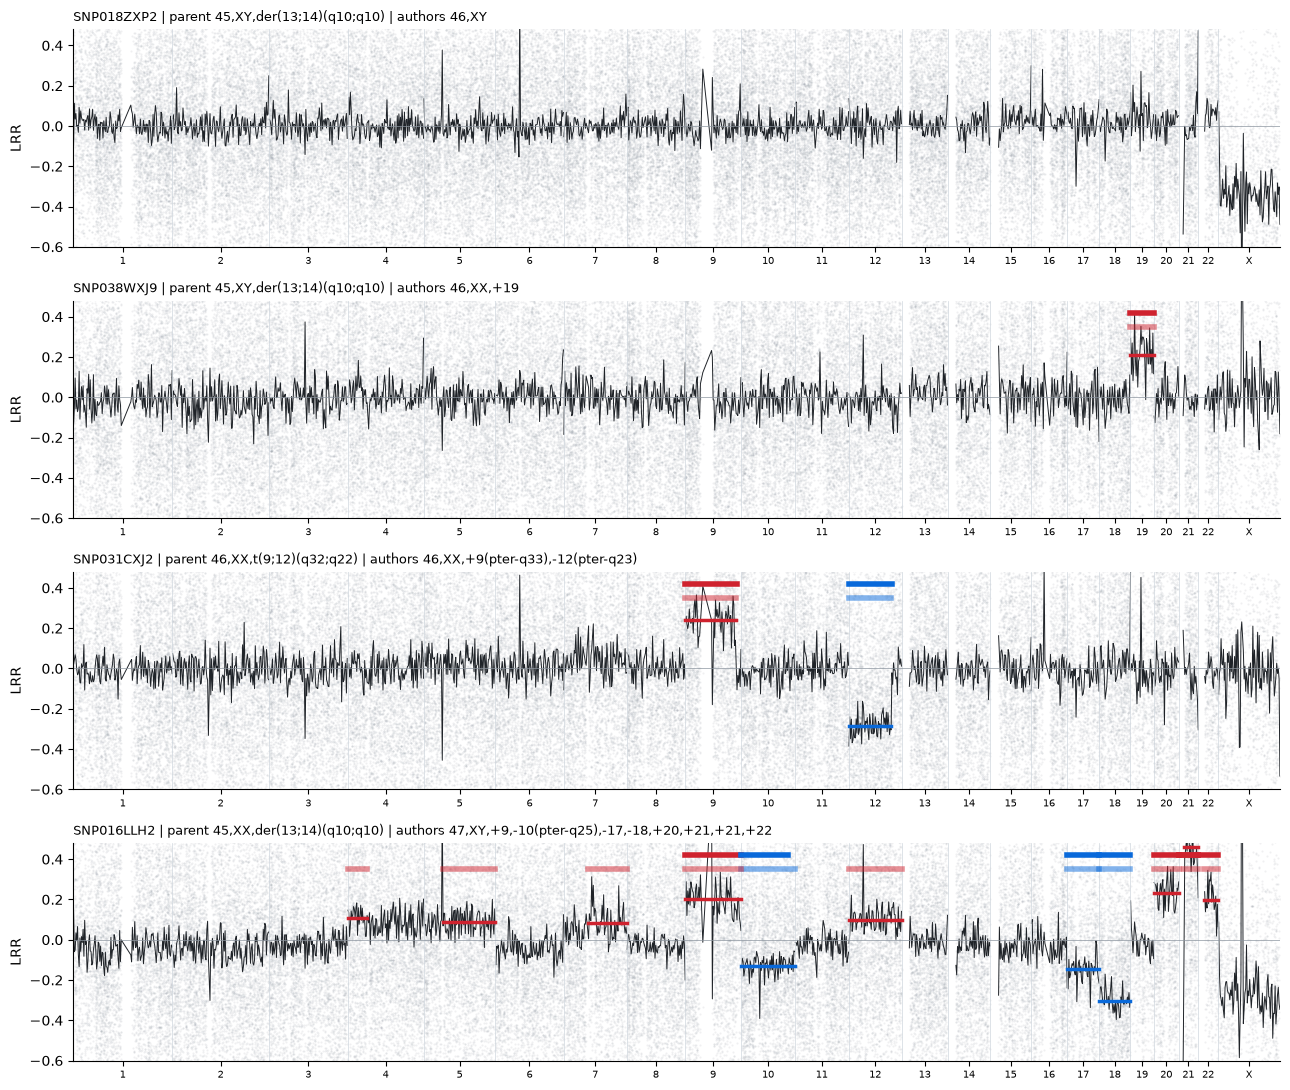

In [30]:
offset = {}
running = 0
for chrom in CHROMS:
    offset[chrom] = running
    running += CHRLEN[chrom]
GENOME_LENGTH = running
genome_x = snps["chr"].map(offset).to_numpy() + POS


def event_color(kind):
    if kind == "gain":
        return GAIN_COLOR
    return LOSS_COLOR


def plot_genome(gsm, ax):
    j = SAMPLES.index(gsm)
    info = meta[meta["gsm"] == gsm].iloc[0]
    ax.scatter(genome_x[::3], LRR[::3, j], s=0.2, c=GREY, alpha=0.15, rasterized=True)
    for chrom in CHROMS:                                          # 2-Mb running median
        on_chrom = (snps["chr"] == chrom).to_numpy()
        bins = (POS[on_chrom] // 2e6).astype(int)
        medians = pd.Series(LRR[on_chrom, j]).groupby(bins).median()
        ax.plot(offset[chrom] + medians.index * 2e6 + 1e6, medians.values, color=INK, lw=0.7)
        ax.axvline(offset[chrom], color="#d0d7de", lw=0.5)
    for chrom, start, end, kind, label in info["events_author"]:  # authors' events (upper bar)
        ax.plot([offset[chrom] + start, offset[chrom] + end], [0.42, 0.42], color=event_color(kind), lw=4)
    for _, ev in events[events["sample"] == gsm].iterrows():      # my events (lower bar + level line)
        x0 = offset[ev["chr"]] + ev["start"]
        x1 = offset[ev["chr"]] + ev["end"]
        expected = D_GAIN if ev["type"] == "gain" else D_LOSS
        ax.plot([x0, x1], [0.35, 0.35], color=event_color(ev["type"]), lw=4, alpha=0.5)
        ax.plot([x0, x1], [ev["level"] * expected, ev["level"] * expected], color=event_color(ev["type"]), lw=2.5)
    ax.set_xticks([offset[c] + CHRLEN[c] / 2 for c in CHROMS])
    ax.set_xticklabels(CHROMS, fontsize=7)
    ax.set_xlim(0, GENOME_LENGTH)
    ax.set_ylim(-0.6, 0.48)
    ax.axhline(0, color=GREY, lw=0.5)
    ax.set_ylabel("LRR")
    ax.set_title(f"{info['title']} | parent {info['parent_karyotype']} | authors {info['author_result']}",
                 loc="left", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)


examples = ["SNP018ZXP2", "SNP038WXJ9", "SNP031CXJ2", "SNP016LLH2"]   # normal / +19 / t(9;12) / complex
fig, axes = plt.subplots(len(examples), 1, figsize=(13, 11))
for ax, title in zip(axes, examples):
    gsm = meta[meta["title"] == title]["gsm"].iloc[0]
    plot_genome(gsm, ax)
plt.tight_layout()
plt.show()

## 7. Comparison with existing methods
**Question:** is the trade-off seen in block 6 specific to my method?

All methods get the **same corrected LRR**. "Calibrated rule" = the calling rule of 5.2 (`call_states`): noise σ
re-estimated from each method's own segment medians per size class, call if |median| > max(4σ, 0.25·|d|), the
male-X one-copy scale d, the same size filter and merging. So a row "X + calibrated rule" compares
*segmentation + calibration*, not segmentation alone.
* **DNAcopy CBS** (Olshen et al. 2004), two settings, both with the calibrated rule: α = 0.001 without undo
  (`cbs_noundo`), and the DNAcopy defaults α = 0.01 with `undo.splits = "sdundo"`, undo.SD = 3 (`cbs_default`).
* **Conventional fixed cut-offs** |median| > 0.10 / 0.15 / 0.20 on the `cbs_noundo` segments (instead of the
  calibrated rule).
* **PennCNV** 1.0.5 (Wang et al. 2007): joint LRR+BAF HMM with the stock Affymetrix 6.0 model, run on a separate
  server - results loaded from `precomputed/` (command below).

In [31]:
CBS_SEGMENTS = """
suppressPackageStartupMessages({ library(DNAcopy); library(data.table) })
args <- commandArgs(TRUE)
lrr_file <- args[1]; cyto_file <- args[2]; out_file <- args[3]
alpha <- as.numeric(args[4]); undo_sd <- as.numeric(args[5])        # undo_sd = 0 -> no undo step
d <- fread(cmd = paste("gzip -dc", shQuote(lrr_file)))
d <- d[chr != "X"]
cyto <- fread(cmd = paste("gzip -dc", shQuote(cyto_file)), header = FALSE)
cen <- cyto[V5 == "acen", .(cen_start = min(V2)), by = .(chr = sub("chr", "", V1))]
d <- merge(d, cen, by = "chr")
d[, arm := paste0(chr, ifelse(pos < cen_start, "p", "q"))]
samples <- setdiff(names(d), c("snp", "chr", "pos", "cen_start", "arm"))
out <- list()
for (s in samples) {
  cna <- smooth.CNA(CNA(d[[s]], d$arm, d$pos, data.type = "logratio", sampleid = s))
  undo <- if (undo_sd > 0) "sdundo" else "none"
  seg <- segment(cna, alpha = alpha, min.width = 5, undo.splits = undo, undo.SD = max(undo_sd, 1), verbose = 0)$output
  out[[s]] <- data.table(sample = s, arm = seg$chrom, start = seg$loc.start, end = seg$loc.end, nsnp = seg$num.mark)
}
fwrite(rbindlist(out), out_file, sep = "\\t")
"""
cbs_settings = {"cbs_noundo": (0.001, 0), "cbs_default": (0.01, 3)}
cbs_segments = {}
for name in cbs_settings:
    alpha, undo_sd = cbs_settings[name]
    seg_file = RES / f"segments_{name}.tsv"
    if not seg_file.exists():
        if RUN_SLOW:
            run_r(CBS_SEGMENTS, [lrr_file, DATA / "hg19.cytoBand.txt.gz", seg_file, alpha, undo_sd], "cbs")
        else:
            seg_file = PRE / f"segments_{name}.tsv"            # computed with exactly this code
    table = pd.read_csv(seg_file, sep="\t")
    cbs_segments[name] = add_segment_medians(table[["sample", "arm", "start", "end", "nsnp"]])

cbs_calls = call_states(cbs_segments["cbs_noundo"])
comparison["DNAcopy CBS + calibrated rule"] = summarise(per_biopsy_agreement(cbs_calls))
cbs_default_calls = call_states(cbs_segments["cbs_default"])
comparison["DNAcopy a=.01, sdundo=3 + calibrated rule"] = summarise(per_biopsy_agreement(cbs_default_calls))
for cutoff in [0.10, 0.15, 0.20]:
    fixed_calls = call_states(cbs_segments["cbs_noundo"], fixed_cutoff=cutoff)
    comparison[f"CBS + fixed cut-off |{cutoff:.2f}|"] = summarise(per_biopsy_agreement(fixed_calls))

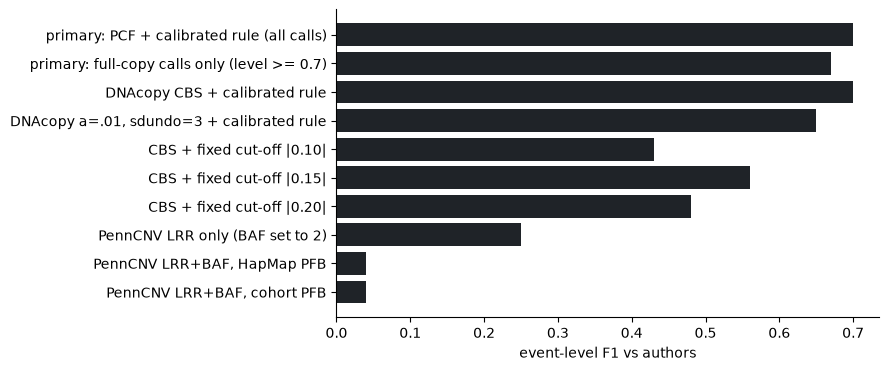

,abnormal_detected,normal_called_normal,arm_sensitivity,extra_arm_calls,events_matched,event_recall,event_precision,F1
primary: PCF + calibrated rule (all calls),14/14,28/33,0.95,27,32/36,0.89,0.57,0.7
primary: full-copy calls only (level >= 0.7),11/14,33/33,0.63,0,19/36,0.53,0.9,0.67
DNAcopy CBS + calibrated rule,14/14,26/33,0.93,17,32/36,0.89,0.57,0.7
"DNAcopy a=.01, sdundo=3 + calibrated rule",14/14,25/33,0.95,25,32/36,0.89,0.52,0.65
CBS + fixed cut-off |0.10|,14/14,15/33,0.95,13,33/36,0.92,0.28,0.43
CBS + fixed cut-off |0.15|,14/14,26/33,0.78,0,26/36,0.72,0.46,0.56
CBS + fixed cut-off |0.20|,11/14,29/33,0.54,0,16/36,0.44,0.52,0.48
PennCNV LRR only (BAF set to 2),13/14,28/33,0.44,0,12/36,0.33,0.2,0.25
"PennCNV LRR+BAF, HapMap PFB",4/14,33/33,0.02,0,1/36,0.03,0.09,0.04
"PennCNV LRR+BAF, cohort PFB",5/14,33/33,0.05,0,1/36,0.03,0.08,0.04


In [32]:
def read_penncnv(path):
    """PennCNV .rawcnv -> events. Same >=3 Mb / >=100 SNP filter as above; same-direction calls on one chromosome
    closer than 5 Mb are merged (PennCNV fragments long low-signal events)."""
    pattern = r"chr(\w+):(\d+)-(\d+)\s+numsnp=(\d+)\s+\S+\s+state\d,cn=(\d)\s+(\S+)"
    raw_calls = []
    for line in open(path):
        match = re.match(pattern, line)
        if match is None:
            continue
        chrom, start, end, nsnp, copy_number, signal_file = match.groups()
        if int(copy_number) == 2:                                   # copy-neutral LOH states: not scored
            continue
        kind = "gain" if int(copy_number) > 2 else "loss"
        raw_calls.append({"sample": Path(signal_file).stem, "chr": chrom, "start": int(start), "end": int(end),
                          "nsnp": int(nsnp), "type": kind})
    columns = ["sample", "chr", "start", "end", "nsnp", "type"]
    if len(raw_calls) == 0:
        return pd.DataFrame(columns=columns)
    raw_calls = pd.DataFrame(raw_calls).sort_values(["sample", "chr", "type", "start"])
    merged = []
    for (sample, chrom, kind), group in raw_calls.groupby(["sample", "chr", "type"]):
        current = None
        for row in group.itertuples():
            if current is not None and row.start - current["end"] < 5e6:
                current["end"] = max(current["end"], row.end)
                current["nsnp"] += row.nsnp
                continue
            if current is not None:
                merged.append(current)
            current = {"sample": sample, "chr": chrom, "start": row.start, "end": row.end, "nsnp": row.nsnp, "type": kind}
        merged.append(current)
    merged = pd.DataFrame(merged)
    keep = (merged["end"] - merged["start"] >= 3e6) & (merged["nsnp"] >= 100) & (merged["chr"] != "X")
    return merged[keep]


penncnv_runs = {"PennCNV LRR only (BAF set to 2)": "lrr_only.rawcnv",
                "PennCNV LRR+BAF, HapMap PFB": "joint_popPFB.rawcnv",
                "PennCNV LRR+BAF, cohort PFB": "joint_cohortPFB.rawcnv"}
for name in penncnv_runs:
    penncnv_calls = read_penncnv(PRE / penncnv_runs[name])
    comparison[name] = summarise(per_biopsy_agreement(penncnv_calls))

comparison_table = pd.DataFrame(comparison).T
f1_values = comparison_table["F1"].astype(float)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(f1_values.index[::-1], f1_values.values[::-1], color=INK)
ax.set_xlabel("event-level F1 vs authors")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
comparison_table

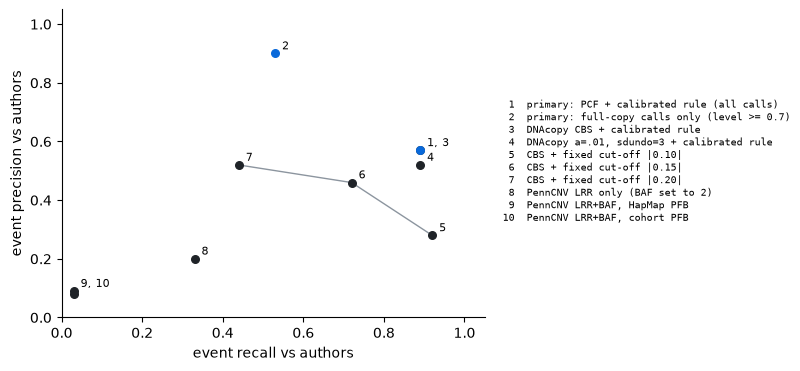

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
fixed_names = [n for n in comparison_table.index if n.startswith("CBS + fixed")]
ax.plot(comparison_table.loc[fixed_names, "event_recall"].astype(float),
        comparison_table.loc[fixed_names, "event_precision"].astype(float), color=GREY, lw=1, zorder=1)

# number the methods; methods at (almost) the same point share one label, e.g. "1, 3"
labels_at = {}
key_lines = []
for number, name in enumerate(comparison_table.index, start=1):
    recall = float(comparison_table.loc[name, "event_recall"])
    precision = float(comparison_table.loc[name, "event_precision"])
    is_primary = name.startswith("primary")
    ax.scatter(recall, precision, color=LOSS_COLOR if is_primary else INK, s=30, zorder=3 if is_primary else 2)
    point = (round(recall, 1), round(precision, 1))
    if point not in labels_at:
        labels_at[point] = [recall, precision, []]
    labels_at[point][2].append(str(number))
    key_lines.append(f"{number:>2}  {name}")
for recall, precision, numbers in labels_at.values():
    ax.annotate(", ".join(numbers), (recall, precision), fontsize=8, xytext=(5, 3), textcoords="offset points")

ax.set_xlim(0, 1.05)
ax.set_ylim(0, 1.05)
ax.set_xlabel("event recall vs authors")
ax.set_ylabel("event precision vs authors")
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(left=0.08, right=0.55)
fig.text(0.57, 0.5, "\n".join(key_lines), fontsize=7.5, va="center", family="monospace")
plt.show()

**Observed:**
* **Fixed cut-offs depend on the chosen number.** With |median| > 0.10 almost every author event is found (recall
  0.92), but only 15/33 normal biopsies stay normal. With 0.20 the normals are clean (29/33), but most author events
  are missed (recall 0.44). There is no way to pick the "right" cut-off without looking at the answers. My rule
  sets the threshold from the noise of the data and gets recall 0.89 with 26-28/33 normals clean.
* **CBS gives the same result as PCF** when both use my rule (F1 0.70 for both). So the segmentation method matters
  less than how the threshold is set.
* **DNAcopy with its usual settings (`sdundo`) is worse** (precision 0.52, 25/33 normals clean). `sdundo` removes a
  breakpoint if the two neighbouring segments differ by less than 3 x the noise of a single SNP, i.e. ~1.5 LRR. A
  real one-copy change here is only 0.2-0.3 LRR, so many real breakpoints are removed.
* **PennCNV does not work on these data.** Its ready-made model was trained on normal, unamplified DNA. With BAF it
  finds 1 of 36 author events (the noisy BAF of block 4 makes losses look heterozygous); with LRR only it finds
  12/36 and cuts events into pieces, because it expects a one-copy loss near -1, not -0.3.

**Decision:** keep PCF + my rule. The comparison with the authors cannot tell PCF and CBS apart.
**Next question:** which segmenter finds more events when the truth is known? -> simulations in block 8.

PennCNV command (Linux): `detect_cnv.pl -test -hmm affy/libgw6/affygw6.hmm -pfb <pfb> -list signals.list -out out.rawcnv`
with signal files `Name, Chr, Position, <sample>.Log R Ratio, <sample>.B Allele Freq` from this notebook's LRR/BAF.

## 8. What can the method detect? Simulated steps in real profiles
**Question:** what sizes and amplitudes can be detected at all, and which segmenter does better? (Comparison between PCF and CBS as they were both good.)

Into real LRR profiles of biopsies called normal both by me and by the authors (so background selection uses the GEO
labels), I add a step of `amplitude × one-copy shift` (0.25-1×) over 2-40 Mb, re-segment that arm with the same
method and frozen rule, and record whether it is called. Real WGA noise and waves are kept. First, one example:

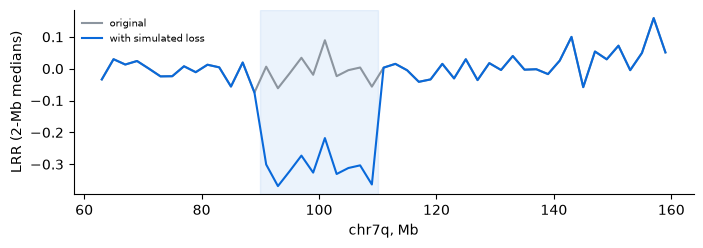

In [34]:
called_biopsies = set(events["sample"])
normal_biopsies = []
for row in meta.itertuples():
    if row.author_class.startswith("normal") and row.gsm not in called_biopsies:
        normal_biopsies.append(row.gsm)

j = SAMPLES.index(normal_biopsies[0])
on_7q = ((snps["chr"] == "7") & (snps["pos"] > CEN_END["7"])).to_numpy()
x_mb = POS[on_7q] / 1e6
original = LRR[on_7q, j]
simulated = original.copy()
simulated[(x_mb > 90) & (x_mb < 110)] += D_LOSS                  # a full-copy 20-Mb loss
fig, ax = plt.subplots(figsize=(8, 2.4))
for values, color, label in [(original, GREY, "original"), (simulated, LOSS_COLOR, "with simulated loss")]:
    medians = pd.Series(values).groupby((x_mb // 2).astype(int)).median()
    ax.plot(medians.index * 2 + 1, medians.values, color=color, label=label)
ax.axvspan(90, 110, color=LOSS_COLOR, alpha=0.08)
ax.set_xlabel("chr7q, Mb")
ax.set_ylabel("LRR (2-Mb medians)")
ax.legend(fontsize=7, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Now the grid. This run: PCF, 5 replicates per cell. The full grid (20 replicates; PCF and two CBS
variants, with endpoint errors and extra calls) was computed with the same procedure and is loaded from `precomputed/`.

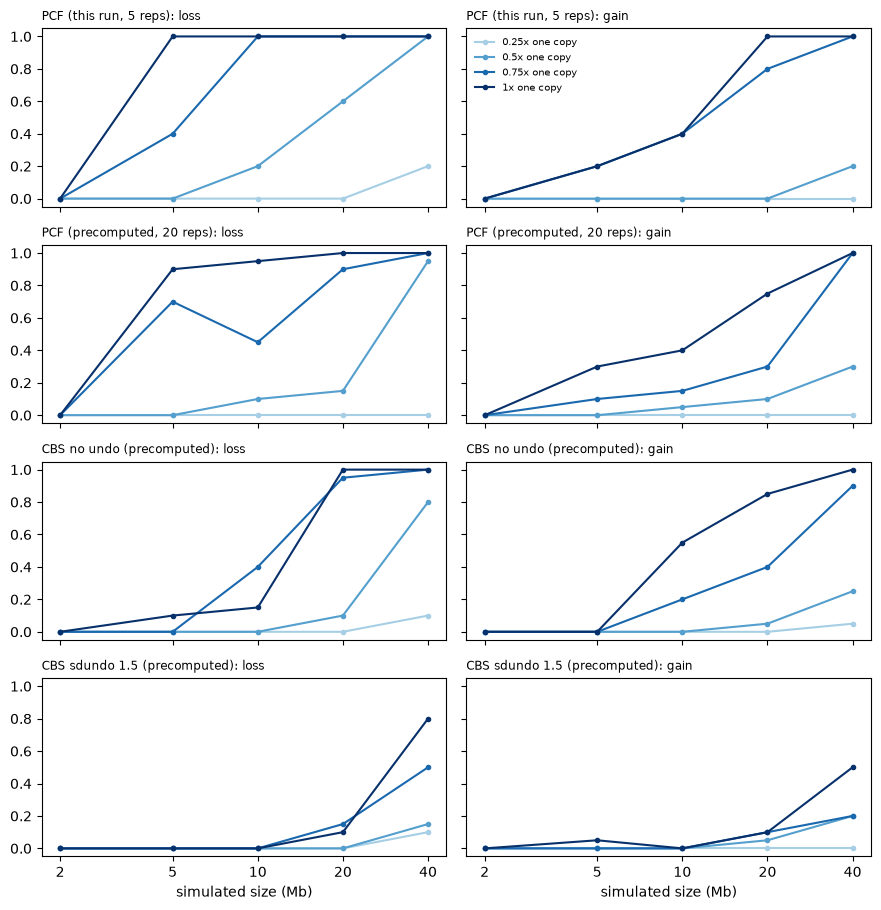

,detected (all cells),full copy >=10 Mb,"median endpoint error, Mb (detected only)",extra calls per simulation
run,,,,
"PCF (this run, 5 reps)",0.36,0.90,NaN,NaN
"PCF (precomputed, 20 reps)",0.31,0.85,0.25,0.0
CBS no undo (precomputed),0.25,0.76,0.40,0.0
CBS sdundo 1.5 (precomputed),0.08,0.25,9.71,0.0


In [35]:
SPIKE_IN = """
suppressPackageStartupMessages({ library(DNAcopy); library(copynumber); library(data.table) })
args <- commandArgs(TRUE)
lrr_file <- args[1]; cyto_file <- args[2]; out_file <- args[3]; method <- args[4]
n_rep <- as.integer(args[5]); d_loss <- as.numeric(args[6]); d_gain <- as.numeric(args[7])
sigma <- as.numeric(strsplit(args[8], ",")[[1]]); normals <- strsplit(args[9], ",")[[1]]

d <- fread(cmd = paste("gzip -dc", shQuote(lrr_file)))
d <- d[chr != "X"]
cyto <- fread(cmd = paste("gzip -dc", shQuote(cyto_file)), header = FALSE)
cen <- cyto[V5 == "acen", .(cen_start = min(V2)), by = .(chr = sub("chr", "", V1))]
d <- merge(d, cen, by = "chr")
d[, arm := paste0(chr, ifelse(pos < cen_start, "p", "q"))]
arms <- d[, .(start = min(pos), end = max(pos), n = .N), by = arm][(end - start) > 45e6 & n > 1500]

threshold <- function(mb, type) {                      # calibrated rule, fixed
  s <- if (mb < 10) sigma[1] else if (mb < 30) sigma[2] else sigma[3]
  if (type == "loss") -max(4 * s, 0.25 * abs(d_loss)) else max(4 * s, 0.25 * d_gain)
}

set.seed(1)
grid <- CJ(L = c(2, 5, 10, 20, 40), amp = c(0.25, 0.5, 0.75, 1), type = c("gain", "loss"), rep = 1:n_rep)
results <- list()
for (i in seq_len(nrow(grid))) {
  g <- grid[i]
  s <- sample(normals, 1)
  chosen <- arms[sample(.N, 1)]
  start <- runif(1, chosen$start, chosen$end - g$L * 1e6)
  end <- start + g$L * 1e6
  x <- d[arm == chosen$arm][order(pos)]
  ok <- is.finite(x[[s]])
  pos <- x$pos[ok]
  y <- x[[s]][ok]
  inside <- pos >= start & pos <= end
  y[inside] <- y[inside] + g$amp * ifelse(g$type == "loss", d_loss, d_gain)
  if (method == "cbs") {
    seg <- segment(CNA(y, rep(chosen$arm, length(y)), pos, data.type = "logratio"),
                   alpha = 0.001, min.width = 5, verbose = 0)$output
  } else {
    one_arm <- data.frame(chrom = as.integer(sub("[pq]$", "", chosen$arm)), pos = pos, s = y)
    p <- pcf(winsorize(one_arm, assembly = "hg19", verbose = FALSE), Y = one_arm, assembly = "hg19",
             gamma = 40, kmin = 5, normalize = TRUE, fast = TRUE, verbose = FALSE)
    seg <- data.frame(loc.start = p$start.pos, loc.end = p$end.pos, num.mark = p$n.probes)
  }
  seg$call <- "none"
  for (k in seq_len(nrow(seg))) {
    mb <- (seg$loc.end[k] - seg$loc.start[k]) / 1e6
    if (mb < 3 || seg$num.mark[k] < 100) next
    seg_median <- median(y[pos >= seg$loc.start[k] & pos <= seg$loc.end[k]])   # median, as for real segments
    if (seg_median < threshold(mb, "loss")) seg$call[k] <- "loss"
    if (seg_median > threshold(mb, "gain")) seg$call[k] <- "gain"
  }
  hits <- seg[seg$call == g$type, ]
  overlap <- sum(pmax(0, pmin(end, hits$loc.end) - pmax(start, hits$loc.start)))
  results[[i]] <- data.table(g, detected = overlap >= 0.5 * (end - start))
}
fwrite(rbindlist(results), out_file, sep = "\\t")
"""
spike_file = RES / "spikein_pcf_small.tsv"
if not spike_file.exists():
    sigma_text = ",".join(str(s) for s in sigmas)
    run_r(SPIKE_IN, [lrr_file, DATA / "hg19.cytoBand.txt.gz", spike_file, "pcf", 5, D_LOSS, D_GAIN,
                     sigma_text, ",".join(normal_biopsies)], "spikein")

spike_runs = {"PCF (this run, 5 reps)": pd.read_csv(spike_file, sep="\t"),
              "PCF (precomputed, 20 reps)": pd.read_csv(PRE / "spikein_pcf_full.tsv", sep="\t"),
              "CBS no undo (precomputed)": pd.read_csv(PRE / "spikein_cbs_noundo_full.tsv", sep="\t"),
              "CBS sdundo 1.5 (precomputed)": pd.read_csv(PRE / "spikein_cbs_sdundo_full.tsv", sep="\t")}

fig, axes = plt.subplots(len(spike_runs), 2, figsize=(9, 2.3 * len(spike_runs)), sharex=True, sharey=True)
for i, name in enumerate(spike_runs):
    run = spike_runs[name].rename(columns={"typ": "type"})        # older precomputed files use 'typ'
    for k, kind in enumerate(["loss", "gain"]):
        ax = axes[i, k]
        one_type = run[run["type"] == kind]
        rate = one_type.groupby(["L", "amp"])["detected"].mean()
        detection = rate.unstack()                                       # rows: size, columns: amplitude
        for n, amplitude in enumerate(detection.columns):
            shade = plt.cm.Blues(0.35 + 0.65 * n / 3)
            ax.plot(detection.index, detection[amplitude], marker="o", ms=3, color=shade, label=f"{amplitude:g}x one copy")
        ax.set_xscale("log")
        ax.minorticks_off()                                      # keep only the 2/5/10/20/40 labels
        ax.set_title(f"{name}: {kind}", loc="left", fontsize=8.5)
axes[-1, 0].set_xticks([2, 5, 10, 20, 40])
axes[-1, 0].set_xticklabels([2, 5, 10, 20, 40])
axes[-1, 0].set_xlabel("simulated size (Mb)")
axes[-1, 1].set_xlabel("simulated size (Mb)")
axes[0, 1].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

rows = []
for name in spike_runs:
    run = spike_runs[name]
    row = {"run": name,
           "detected (all cells)": run["detected"].mean(),
           "full copy >=10 Mb": run[(run["amp"] == 1) & (run["L"] >= 10)]["detected"].mean()}
    if "endpoint_err_mb" in run.columns:                           # full precomputed runs only
        row["median endpoint error, Mb (detected only)"] = run[run["detected"]]["endpoint_err_mb"].median()
        row["extra calls per simulation"] = run["other_calls"].mean()
    rows.append(row)
pd.DataFrame(rows).set_index("run").round(2)

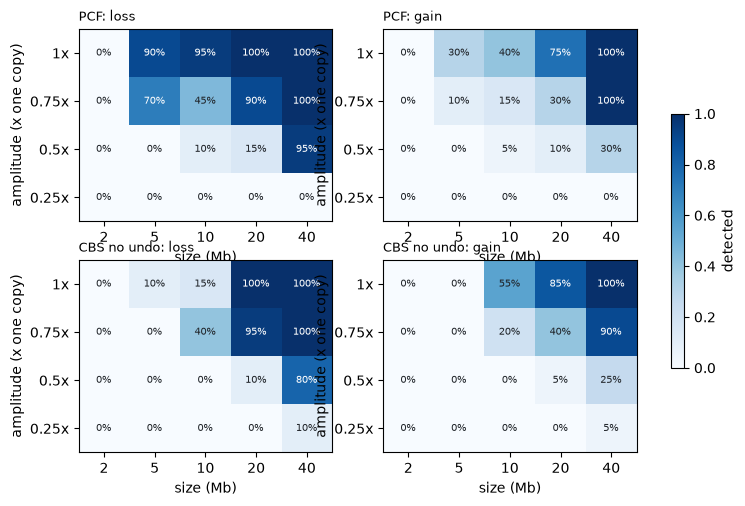

In [36]:
heatmap_runs = ["PCF (precomputed, 20 reps)", "CBS no undo (precomputed)"]
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for i, name in enumerate(heatmap_runs):
    run = spike_runs[name].rename(columns={"typ": "type"})
    for k, kind in enumerate(["loss", "gain"]):
        one_type = run[run["type"] == kind]
        rate = one_type.groupby(["amp", "L"])["detected"].mean().unstack()   # rows: amplitude, columns: size
        image = axes[i, k].imshow(rate.values, origin="lower", cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for a in range(rate.shape[0]):
            for b in range(rate.shape[1]):
                value = rate.values[a, b]
                axes[i, k].text(b, a, f"{value:.0%}", ha="center", va="center", fontsize=7,
                                color="white" if value > 0.6 else INK)
        axes[i, k].set_xticks(range(rate.shape[1]))
        axes[i, k].set_xticklabels([f"{x:g}" for x in rate.columns])
        axes[i, k].set_yticks(range(rate.shape[0]))
        axes[i, k].set_yticklabels([f"{y:g}x" for y in rate.index])
        axes[i, k].set_title(f"{name.split(' (')[0]}: {kind}", loc="left", fontsize=9)
        axes[i, k].set_xlabel("size (Mb)")
        axes[i, k].set_ylabel("amplitude (x one copy)")
fig.colorbar(image, ax=axes, shrink=0.6, label="detected")
plt.show()

**Reading the simulations.** Full-copy losses ≥5 Mb are found almost always; gains (compressed to +0.18) need
≥20-40 Mb; half-amplitude signals only at 40 Mb. PCF finds more than CBS, with more accurate ends at similarly low
observed extra-call rates -> PCF is the primary segmenter. These are conditional analytical limits on processed LRR
with selected backgrounds - not clinical sensitivity and not mosaic cell-fraction limits.

**Decision:** PCF is the primary segmenter (under the tested conditions).
**Next question:** so far the parental karyotypes were not used; they tell where an unbalanced translocation should
show up. Do the imbalances sit there?

## 9. Using the parents' karyotypes
### 9.1 Breakpoint-aware dosage test
**Question:** do the imbalances sit where the parental translocation predicts? **Expectation:** carrier embryos with unbalanced segregation show opposite changes on the two translocated chromosomes.

For each biopsy, the two translocated chromosomes are split at the **parental breakpoints** into centric and distal
segments (Robertsonian: the two q arms). Each segment's median LRR is compared with the **same segment in biopsies of
other couples** (a locus-matched null: same probes, same waves). The sign pattern is then read as *compatible with* a
segregation mode: adjacent-1 (distal segments opposite), adjacent-2 (centric segments opposite), Robertsonian
trisomy/monosomy.

In [37]:
def translocation_segments(parent):
    """List of (label, chrom, start, end, is_distal) for the two translocated chromosomes."""
    out = []
    if parent["kind"] == "rob":
        for chrom in parent["chroms"]:
            out.append((chrom + "q", chrom, CEN_END[chrom], CHRLEN[chrom], False))
        return out
    for i in range(2):
        chrom, breakpoint = parent["breakpoints"][i]
        band = parent["bands"][i]
        p_side_is_distal = band[0] == "p"                          # breakpoint on p: the p-terminal piece moves
        out.append((f"{chrom}pter-{band}", chrom, 0, breakpoint, p_side_is_distal))
        out.append((f"{chrom}{band}-qter", chrom, breakpoint, CHRLEN[chrom], not p_side_is_distal))
    return out


rows = []
for row in meta.itertuples():
    j = SAMPLES.index(row.gsm)
    null_columns = []
    for other in meta[meta["couple"] != row.couple]["gsm"]:
        null_columns.append(SAMPLES.index(other))
    for label, chrom, start, end, is_distal in translocation_segments(row.parent):
        in_segment = ((snps["chr"] == chrom) & (snps["pos"] >= start) & (snps["pos"] < end)).to_numpy()
        value = np.nanmedian(LRR[in_segment, j])
        null_values = np.nanmedian(LRR[in_segment][:, null_columns], axis=0)
        null_median = np.median(null_values)
        null_sd = max(1.4826 * np.median(np.abs(null_values - null_median)), 1e-3)
        z = (value - null_median) / null_sd
        shift = value - null_median
        state = "normal"
        if z > 4 and shift > 0.25 * D_GAIN:
            state = "gain"
        if z < -4 and shift < 0.25 * D_LOSS:
            state = "loss"
        rows.append({"title": row.title, "kind": row.parent["kind"], "segment": label, "distal": is_distal,
                     "lrr": round(value, 3), "z": round(z, 1), "state": state})
breakpoint_test = pd.DataFrame(rows)


def read_pattern(group):
    """Translate the segment states of one biopsy into a 'compatible with' label."""
    changed = group[group["state"] != "normal"]
    if len(changed) == 0:
        return "no imbalance on translocated chromosomes"
    labels = []
    chroms = set()
    for row in changed.itertuples():
        labels.append(("+" if row.state == "gain" else "-") + row.segment)
        chroms.add(re.match(r"^(\d+|X)", row.segment).group(1))
    text = ", ".join(labels)
    if group["kind"].iloc[0] == "rob":
        return f"Robertsonian-compatible ({text})"
    opposite_on_two_chroms = len(changed) == 2 and set(changed["state"]) == {"gain", "loss"} and len(chroms) == 2
    if opposite_on_two_chroms and changed["distal"].all():
        return f"adjacent-1-compatible ({text})"
    if opposite_on_two_chroms and not changed["distal"].any():
        return f"adjacent-2-compatible ({text})"
    return f"other ({text})"


patterns = {}
for title, group in breakpoint_test.groupby("title"):
    patterns[title] = read_pattern(group)
pattern_table = meta.set_index("title")[["parent_karyotype", "author_class", "author_result"]].copy()
pattern_table["dosage_pattern"] = pd.Series(patterns)
pattern_table[pattern_table["dosage_pattern"] != "no imbalance on translocated chromosomes"]

,parent_karyotype,author_class,author_result,dosage_pattern
title,,,,
SNP027YLQ8,"46,XY,t(6;22)(q12;p11.2)",normal female,"46,XX","other (+6pter-q12, +6q12-qter)"
SNP059LY8,"46,XY,t(2;6)(q35;q21)",normal female,"46,XX","other (+6pter-q21, +6q21-qter)"
SNP011ZJ3,"45,XY,der(13;15)(q10;q10)",Unbalanced translocation,"45,XY,-15",Robertsonian-compatible (-15q)
SNP097LYM5,"45,XY,der(13;14)(q10;q10)",Unbalanced translocation and de novo segmental...,"45,XY,+2q,-14",Robertsonian-compatible (-14q)
SNP093BLY4,"45,XX,der(14;21)(q10;q10)",Unbalanced translocation and de novo aneuploidy,"48,XX,+21,+22",Robertsonian-compatible (+21q)
SNP005XM2,"46,XX,t(1;2)(q23;q31)",Unbalanced translocation and de novo aneuploidy,"XX,+1(q31-qter);-2(q32-qter),-7","adjacent-1-compatible (+1q23-qter, -2q31-qter)"
SNP027YLQ5,"46,XY,t(6;22)(q12;p11.2)",complex aneuploid,"46,XX,-6(q12-qter),+9(p22-p11.3),+10(q21.2-q23...",other (-6q12-qter)
SNP031CXJ2,"46,XX,t(9;12)(q32;q22)",Unbalanced translocation,"46,XX,+9(pter-q33),-12(pter-q23)","other (+9pter-q32, -12pter-q22, -12q22-qter)"
SNP002CL6,"46,XY,t(2;7)(p13;p13)",Unbalanced translocation and de novo segmental...,"46,XX,+2(pter-p16.2),-4(q32.1qter),-7(pter-p14.1)","adjacent-1-compatible (+2pter-p13, -7pter-p13)"


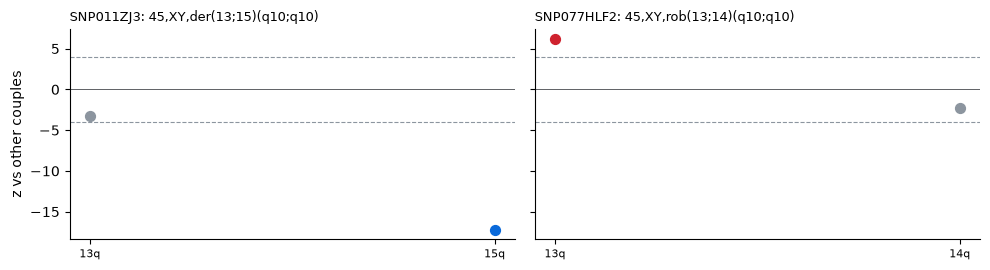

In [38]:
# z-score of each parental segment vs the other couples
cases = ["SNP011ZJ3", "SNP077HLF2"]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, title in zip(axes, cases):
    part = breakpoint_test[breakpoint_test["title"] == title].reset_index(drop=True)
    for i, row in part.iterrows():
        color = GAIN_COLOR if row["state"] == "gain" else LOSS_COLOR if row["state"] == "loss" else GREY
        ax.scatter(i, row["z"], color=color, s=50, zorder=3)
    ax.axhline(4, color=GREY, ls="--", lw=0.8)
    ax.axhline(-4, color=GREY, ls="--", lw=0.8)
    ax.axhline(0, color=INK, lw=0.5)
    ax.set_xticks(range(len(part)))
    ax.set_xticklabels(part["segment"], fontsize=8)
    ax.set_title(f"{title}: {meta[meta['title'] == title]['parent_karyotype'].iloc[0]}", loc="left", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("z vs other couples")
plt.tight_layout()
plt.show()

**How to read the comparison.** We tested whether each embryo's LRR pattern matches the changes expected from the parental rearrangement. The six biopsies the authors classified as unbalanced translocations are the positive comparison group.

- **5/6 strict matches.** Three biopsies have a Robertsonian-compatible pattern and two have an adjacent-1-compatible pattern.
- **1/6 classified as `other`.** SNP031CXJ2 has the proximal chr9 gain and proximal chr12 loss expected for adjacent-2. The test also flags distal 12q, so the profile fails the strict rule of exactly two changes. Section 9.2 shows where this extra flag comes from.
- **29/33 author-normal biopsies had no flags.** The remaining four had at least one flag in the intervals tested. These are candidates for follow-up. A single biopsy cannot resolve whether a weak shift reflects mosaicism or technical variation.

The bars show counts and percentages within each author-defined group. They summarize the breakpoint-aware LRR test in this section. Section 6 reports agreement for the genome-wide PCF calls.


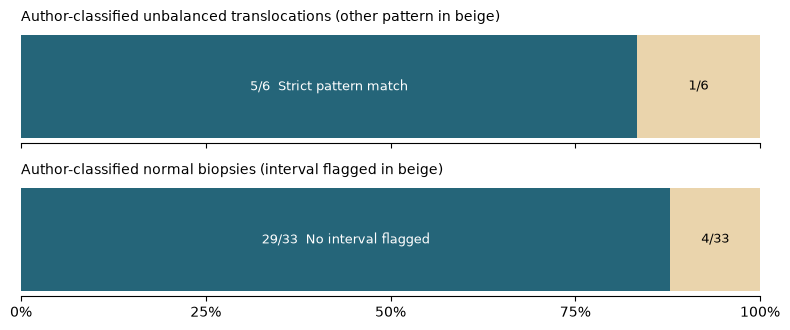

In [39]:
author_class = pattern_table["author_class"].str.lower()
unbalanced = author_class.str.startswith("unbalanced translocation")
normal = author_class.str.startswith("normal")
pattern = pattern_table["dosage_pattern"]
no_flags = pattern.eq("no imbalance on translocated chromosomes")
strict_match = pattern.str.startswith(("Robertsonian-compatible", "adjacent-1-compatible", "adjacent-2-compatible"))

counts = [
    (int((unbalanced & strict_match).sum()), int(unbalanced.sum()),
     "Author-classified unbalanced translocations", "Strict pattern match", "Other pattern"),
    (int((normal & no_flags).sum()), int(normal.sum()),
     "Author-classified normal biopsies", "No interval flagged", "Interval flagged"),
]
fig, axes = plt.subplots(2, 1, figsize=(8, 3.4), sharex=True)
for ax, (count, total, label, matched, remaining) in zip(axes, counts):
    proportion = count / total
    ax.barh(0, proportion, color="#256579", height=0.55)
    ax.barh(0, 1 - proportion, left=proportion, color="#ead4ac", height=0.55)
    ax.text(proportion / 2, 0, f"{count}/{total}  {matched}", color="white", ha="center", va="center", fontsize=9)
    ax.text((1 + proportion) / 2, 0, f"{total - count}/{total}", ha="center", va="center", fontsize=9)
    ax.set_title(f"{label} ({remaining.lower()} in beige)", loc="left", fontsize=10)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[-1].set_xlim(0, 1)
axes[-1].set_xticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"])
fig.tight_layout()
plt.show()


### 9.2 Two biological cases

**1. SNP066CX4 - possible chromosome 12 loss.** The authors classified this biopsy as 46,XX. Our PCF caller flags a loss across almost all of chr12 (0.2-133.8 Mb, level 0.36). The 2 Mb LRR medians are consistently lower across chr12 than along most of the genome. The signal is below the full-copy threshold of 0.7 and warrants follow-up.


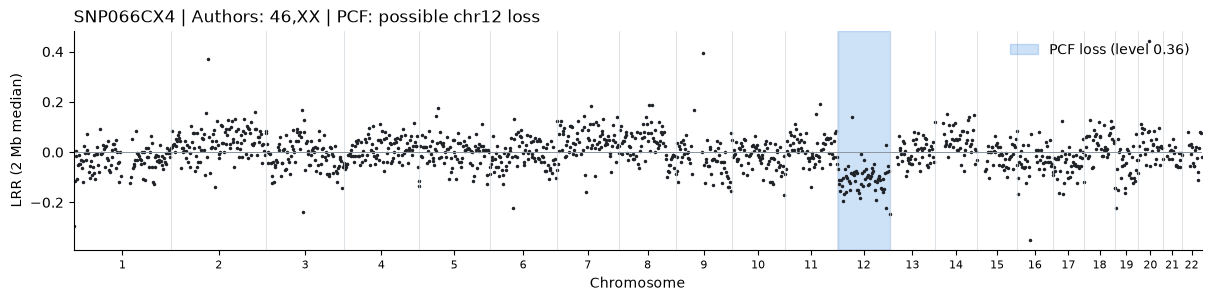

In [40]:
row = meta.loc[meta["title"] == "SNP066CX4"].iloc[0]
sample_index = SAMPLES.index(row["gsm"])
calls = events.loc[(events["sample"] == row["gsm"]) & (events["chr"] == "12")]
fig, ax = plt.subplots(figsize=(12, 2.9), layout="constrained")
offset = 0
centres, labels = [], []
for chrom in CHROMS[:-1]:
    mask = snps["chr"].to_numpy() == chrom
    bins = (POS[mask] // 2_000_000).astype(int)
    medians = pd.Series(LRR[mask, sample_index]).groupby(bins).median()
    ax.plot(offset + medians.index * 2 + 1, medians, ".", color=INK, ms=3)
    ax.axvline(offset, color="#d0d7de", lw=0.5)
    if chrom == "12":
        for call in calls.itertuples(index=False):
            ax.axvspan(offset + call.start / 1e6, offset + call.end / 1e6,
                       color=LOSS_COLOR, alpha=0.2, label=f"PCF loss (level {call.level:.2f})")
    width = CHRLEN[chrom] / 1e6
    centres.append(offset + width / 2)
    labels.append(chrom)
    offset += width
ax.axhline(0, color=GREY, lw=0.7)
ax.set(xlim=(0, offset), ylabel="LRR (2 Mb median)", xlabel="Chromosome")
ax.set_xticks(centres, labels, fontsize=8)
ax.set_title(f"{row.title} | Authors: {row.author_result} | PCF: possible chr12 loss", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper right", frameon=False)
plt.show()


**2. SNP031CXJ2 - t(9;12)(q32;q22), adjacent-2 pattern.** The embryo shows a proximal gain on chr9 and a proximal loss on chr12. These are the two changes expected for adjacent-2. The breakpoint test also flags the distal 12q interval as a loss. Our strict rule requires exactly two flags, so it returns `other` for this embryo.

The chr12 loss extends past the parental q22 breakpoint toward q23, where the authors also place its boundary. The same loss may drive both 12q flags because the test splits the profile at q22. A separate distal loss remains possible if there is a distinct dosage step.


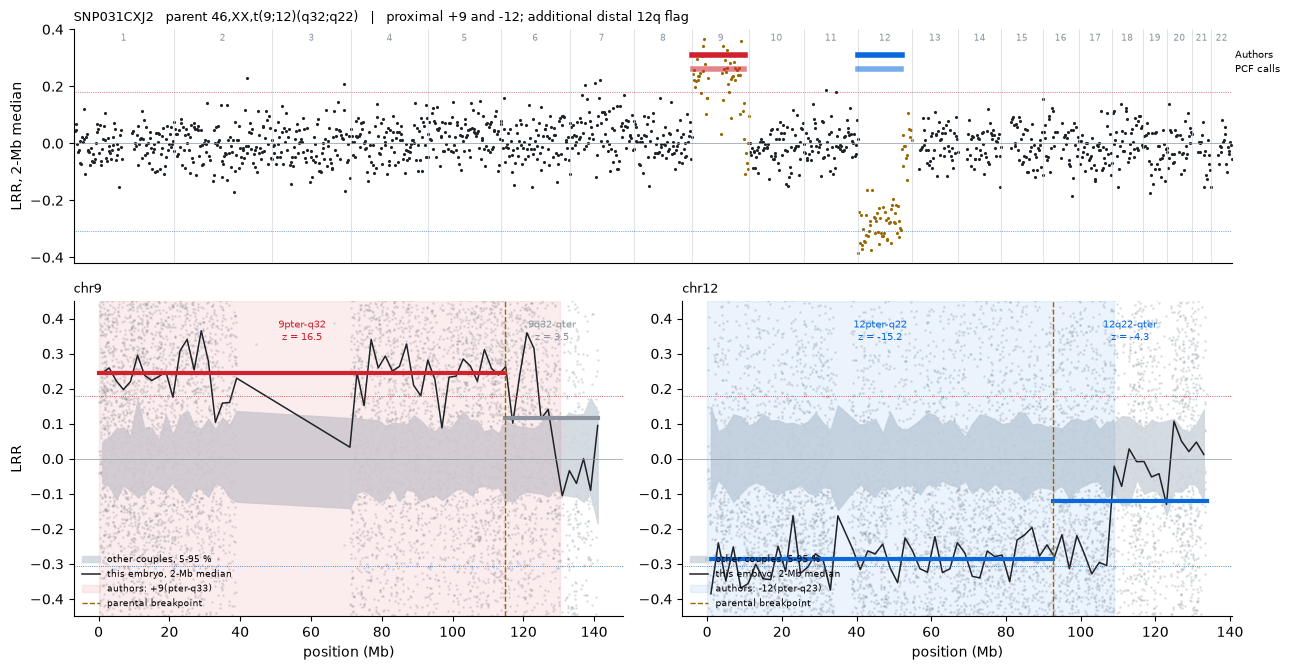

In [41]:
chr_arr = snps["chr"].to_numpy()
BIN = 2e6
offsets, total = {}, 0
for c in CHROMS[:-1]:
    offsets[c] = total
    total += CHRLEN[c]


def bin_medians(rows, columns):
    bins = (POS[rows] // BIN).astype(int)
    centres, values = [], []
    for b in np.unique(bins):
        sel = rows[bins == b]
        if len(sel) < 20:
            continue
        centres.append((b + 0.5) * BIN / 1e6)
        values.append(np.nanmedian(LRR[sel][:, columns], axis=0))
    return np.array(centres), np.array(values)


def kind_color(kind):
    return GAIN_COLOR if kind == "gain" else LOSS_COLOR



def plot_translocation_case(title):
    message = "proximal +9 and -12; additional distal 12q flag"
    row = meta[meta["title"] == title].iloc[0]
    j = SAMPLES.index(row["gsm"])
    others = [SAMPLES.index(g) for g in meta[meta["couple"] != row["couple"]]["gsm"]]
    parent = row["parent"]
    pieces = translocation_segments(parent)
    chroms = []
    for label, c, s, e, d in pieces:
        if c not in chroms:
            chroms.append(c)
    tests = breakpoint_test[breakpoint_test["title"] == title].set_index("segment")

    fig = plt.figure(figsize=(13, 6.8))
    gs = fig.add_gridspec(2, len(chroms), height_ratios=[1, 1.35])
    ax = fig.add_subplot(gs[0, :])
    for c in CHROMS[:-1]:
        x, v = bin_medians(np.where(chr_arr == c)[0], [j])
        ax.plot(offsets[c] / 1e6 + x, v[:, 0], ".", ms=2.5, color="#9a6700" if c in chroms else INK)
        ax.axvline(offsets[c] / 1e6, color="#d0d7de", lw=0.5)
        ax.text((offsets[c] + CHRLEN[c] / 2) / 1e6, 0.36, c, ha="center", fontsize=6.5, color=GREY)
    for c, s, e, kind, lab in row["events_author"]:
        if c in offsets:
            ax.plot([(offsets[c] + s) / 1e6, (offsets[c] + e) / 1e6], [0.31, 0.31], color=kind_color(kind), lw=4)
    for _, ev in events[(events["sample"] == row["gsm"])].iterrows():
        ax.plot([(offsets[ev["chr"]] + ev["start"]) / 1e6, (offsets[ev["chr"]] + ev["end"]) / 1e6], [0.26, 0.26],
                color=kind_color(ev["type"]), lw=4, alpha=0.55)
    ax.text(total / 1e6, 0.31, " Authors", va="center", fontsize=7)
    ax.text(total / 1e6, 0.26, " PCF calls", va="center", fontsize=7)
    ax.axhline(0, color=GREY, lw=0.5)
    ax.axhline(D_GAIN, color=GAIN_COLOR, lw=0.5, ls=":")
    ax.axhline(D_LOSS, color=LOSS_COLOR, lw=0.5, ls=":")
    ax.set_ylim(-0.42, 0.4)
    ax.set_xlim(0, total / 1e6)
    ax.set_xticks([])
    ax.set_ylabel("LRR, 2-Mb median")
    ax.set_title(f"{title}   parent {row['parent_karyotype']}   |   {message}", loc="left", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

    for k, c in enumerate(chroms):
        ax = fig.add_subplot(gs[1, k])
        rows = np.where(chr_arr == c)[0]
        ax.scatter(POS[rows] / 1e6, LRR[rows, j], s=1, color=GREY, alpha=0.2, rasterized=True)
        x, v_oth = bin_medians(rows, others)
        x, v_self = bin_medians(rows, [j])
        ax.fill_between(x, np.nanpercentile(v_oth, 5, axis=1), np.nanpercentile(v_oth, 95, axis=1),
                        color="#d0d7de", alpha=0.9, label="other couples, 5-95 %")
        ax.plot(x, v_self[:, 0], color=INK, lw=1.1, label="this embryo, 2-Mb median")
        for cc, s, e, kind, lab in row["events_author"]:
            if cc == c:
                ax.axvspan(s / 1e6, e / 1e6, color=kind_color(kind), alpha=0.08, label=f"authors: {lab}")
        for label, cc, s, e, distal in pieces:
            if cc != c or label not in tests.index:
                continue
            t = tests.loc[label]
            color = kind_color(t["state"]) if t["state"] != "normal" else GREY
            if np.isfinite(t["lrr"]):
                ax.plot([s / 1e6, e / 1e6], [t["lrr"], t["lrr"]], color=color, lw=3)
                ax.text((s + e) / 2e6, 0.4, f"{label}\nz = {t['z']:g}", ha="center", va="top", fontsize=7.5, color=color)
        if parent["kind"] == "rob":
            ax.axvline(CEN_END[c] / 1e6, color="#9a6700", ls="--", lw=1, label="centromere = fusion point")
        else:
            ax.axvline(dict(parent["breakpoints"])[c] / 1e6, color="#9a6700", ls="--", lw=1, label="parental breakpoint")
        ax.axhline(0, color=GREY, lw=0.5)
        ax.axhline(D_GAIN, color=GAIN_COLOR, lw=0.6, ls=":")
        ax.axhline(D_LOSS, color=LOSS_COLOR, lw=0.6, ls=":")
        ax.set_ylim(-0.45, 0.45)
        ax.set_title(f"chr{c}", loc="left", fontsize=9)
        ax.set_xlabel("position (Mb)")
        ax.spines[["top", "right"]].set_visible(False)
        if k == 0:
            ax.set_ylabel("LRR")
        ax.legend(fontsize=6.5, frameon=False, loc="lower left")
    plt.tight_layout()
    plt.show()


plot_translocation_case("SNP031CXJ2")


## 10. Summary
| Question | Answer from the data |
|---|---|
| Reference without normal arrays? | Leave-one-out cohort median (same WGA chemistry). Excluding siblings from the reference did not change the calls. |
| How large is one copy? | Male chrX: about -0.3 for a loss (theory -1) -> ~3× compression; calibrate on the data. |
| Use BAF? | No: X heterozygosity does not drop in X1-like biopsies; the authors' own GTYPE calls have low call rates and wrong gender in 7/47. |
| Caller | PCF + calibrated rule (male-X scale, empirical-null thresholds). |
| Agreement with the authors | Table in block 6 (biopsy, arm, event level); X dosage 47/47. |
| Existing methods | Calibration matters more than the algorithm; a stock PennCNV model does not transfer to 4-8-cell WGA data. |
| Detection limit (simulated) | Full-copy losses ≥5 Mb; gains ≥20-40 Mb; low-level signals only for very large segments. |
| Parents' karyotypes | Translocation-compatible dosage patterns in all translocation-related embryos. |
| SNP005XM2 - t(1;2)(q23;q31) | Distal 1q gain and 2q loss support adjacent-1 segregation. The dosage steps match the authors’ intervals and lie distal to the mapped parental breakpoints. |
| SNP077HLF2 - rob(13;14) | The caller flags a 13q gain in an embryo classified as normal by the authors. The signal supports a dosage change. Its mechanism and mosaic status remain unresolved. |
